# Make plots


# 1. Setttings
Waveforms are read from the master SDS archive built by `05_download2sds.ipynb` (flovopy.ingest); products are written to the Box `writing/Artemis2` folder. Paths, launch time and channel groups are in `artemis2_config.py`.


In [1]:
from pathlib import Path
import sys
from obspy import read, UTCDateTime, Stream

import artemis2_config as cfg

launchtime = cfg.LAUNCHTIME
duration = cfg.DURATION
pretrigger = cfg.PRETRIGGER
posttrigger = cfg.POSTTRIGGER
starttime = cfg.STARTTIME
endtime = cfg.ENDTIME
starttrim = cfg.STARTTRIM
endtrim = cfg.ENDTRIM

OUT_DIR = cfg.OUT_DIR / "25_make_plots"            # Box .../writing/Artemis2: CSVs, figures, corrected stream
OUT_DIR.mkdir(parents=True, exist_ok=True)
STATION_XLS = cfg.STATION_XLS    # station and launch-pad coordinates
for p in (cfg.STATION_MAP_MODULE_DIR, cfg.ROCKET_MODEL_DIR):
    if str(p) not in sys.path:
        sys.path.append(str(p))

MAKE_STATION_PLOTS = False
CLIP_DATA = False


# 2. Read the launch window from the master SDS archive

In [2]:
# Centaur (DD?, DH?), Gem (HD?), SmartSolo (DP?) and MSFC Guralp/Silicon Audio (DG C*)
st = cfg.get_launch_stream()

# 1R.B29.00.DHZ is zero-filled in the master SDS for days 082-093 (skipped above);
# use the exact counts recovered by restore_B29_DHZ.py, kept outside the master SDS.
if cfg.SKIPPED_FILES:
    print("Skipped unreadable SDS files:", *[p for p, _ in cfg.SKIPPED_FILES], sep="\n  ")
if not st.select(id="1R.B29.00.DHZ"):
    st += cfg.read_restored("1R.B29.00.DHZ")
    st.merge()
print(st)

# get a list of stations, and then subset for each one, and plot
def get_stations(stream):
    return sorted(set(tr.stats.station for tr in stream))

def plot_station_traces(stream, starttime, endtime, equal_scale=False):
    for station in get_stations(stream):
        st_station = stream.select(station=station)
        st_station.plot(type='relative', starttime=starttime, endtime=endtime, show=True, equal_scale=equal_scale);

if MAKE_STATION_PLOTS:
    plot_station_traces(st, starttime=starttrim, endtime=endtrim)

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/ksclib/src/ksclib/data.py:32: UserWarning: SKIPPED unreadable SDS file /Volumes/KSCGTdownld/SDS/2026/1R/B29/DHZ.D/1R.B29.00.DHZ.D.2026.091 (InternalMSEEDParseTimeError)
  warnings.warn(f"SKIPPED unreadable SDS file {path} ({type(exc).__name__})")


Skipped unreadable SDS files:
  /Volumes/KSCGTdownld/SDS/2026/1R/B29/DHZ.D/1R.B29.00.DHZ.D.2026.091
80 Trace(s) in Stream:

1R.B01..DPE | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 500.0 Hz, 2250001 samples
...
(78 other traces)
...
DG.B23.01.CLZ | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 500.0 Hz, 2250001 samples

[Use "print(Stream.__str__(extended=True))" to print all Traces]


# 3. Gem's must be instrument corrected first before any further processing, as otherwise they have giant steps

In [3]:
import gemlog
st_gem = st.select(channel='HD[FI]')
st_gem.detrend(type='demean')
st_gem.filter("highpass", freq=0.05)
for tr in st_gem:
    if 'corrected' in tr.stats:
        continue
    tr = gemlog.deconvolve_gem_response(tr, gain='high') 
    tr.stats['corrected']=True
st_gem.plot(type='relative', starttime=starttrim, endtime=endtrim, show=True, equal_scale=False, outfile=OUT_DIR / 'gem_traces_corrected.png');

# 4. Clip data to remove outliers (if set to True)

In [4]:
import numpy as np

def clip_trace(trace, percentile=99.9):
    '''
    Clip the data in this Trace to +/- 2x the given percentile of the absolute value of the data.
    '''
    x = trace.data
    clip_level = np.nanpercentile(np.abs(x), percentile) * 2
    print(f"Clipping {trace.id} at {clip_level:.2f}")
    trace.data = np.clip(trace.data, -clip_level, clip_level)

def clip_stream(stream, percentile=99.9):
    for tr in stream:
        clip_trace(tr, percentile=percentile)

if CLIP_DATA:
    clip_stream(st, percentile=99.99)

# 5. Remove Trace objects with flat Trace data

These are typically unused sensor inputs

In [5]:
import numpy as np

def is_flat_trace(trace_in, starttime=None, endtime=None, threshold=3.0):

    tr = trace_in.copy()
    tr.detrend(type='linear')
    tr.filter("highpass", freq=0.5)
    if starttime is not None and endtime is not None:
        tr.trim(starttime, endtime)

    data = tr.data.astype(float)

    if len(data) == 0:
        return True

    rms = np.sqrt(np.mean(data**2))
    peak = np.max(np.abs(data))

    if rms == 0:
        return True

    ratio = peak / rms

    return ratio < threshold

THRESHOLD_FLAT = 10.0
st_event = Stream() 
for station in get_stations(st):
    st_station = st.select(station=station)
    if MAKE_STATION_PLOTS:
        st_station.plot(type='relative', starttime=starttime, endtime=endtime, show=True, equal_scale=False);
    for tr in st_station:
        if is_flat_trace(tr, starttrim, endtrim, threshold=THRESHOLD_FLAT):
            print(f"Trace {tr.id} is flat (peak/RMS < {THRESHOLD_FLAT}), skipping.")
        else:
            st_event.append(tr)
print(st_event)


Trace 1R.B03.00.DD1 is flat (peak/RMS < 10.0), skipping.
Trace 1R.B03.00.DD2 is flat (peak/RMS < 10.0), skipping.


Trace 1R.B05.00.DD1 is flat (peak/RMS < 10.0), skipping.
Trace 1R.B05.00.DD2 is flat (peak/RMS < 10.0), skipping.


Trace 1R.B20..HDF is flat (peak/RMS < 10.0), skipping.
Trace 1R.B20.10.HDI is flat (peak/RMS < 10.0), skipping.
Trace 1R.B20S..HDF is flat (peak/RMS < 10.0), skipping.


Trace 1R.B20W..HDF is flat (peak/RMS < 10.0), skipping.


Trace 1R.B29.00.DD1 is flat (peak/RMS < 10.0), skipping.
Trace 1R.B29.00.DD2 is flat (peak/RMS < 10.0), skipping.


Trace 1R.UNK..HD1 is flat (peak/RMS < 10.0), skipping.
69 Trace(s) in Stream:

1R.B01..DPE | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 500.0 Hz, 2250001 samples
...
(67 other traces)
...
1R.B29.00.DHZ | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 500.0 Hz, 2250001 samples

[Use "print(Stream.__str__(extended=True))" to print all Traces]


# 6. Correct Trilliums

In [6]:
# Trillium Compact + Centaur responses from each station's own Centaur response XML
# (latest written before launch); see cfg.centaur_inventory.
st_trillium_corrected = st_event.select(network='1R', station='B*', channel="DH[ZNE12]")

inventories = {}
for tr in st_trillium_corrected:
    if 'corrected' in tr.stats:
        continue
    sta = tr.stats.station
    if sta not in inventories:
        inventories[sta] = cfg.centaur_inventory(sta)
        print(sta, cfg.centaur_response_file(sta).name)
    nyq = 0.5 * tr.stats.sampling_rate
    pre_filt = (0.01, 0.02, 0.94 * nyq, 0.98 * nyq)
    tr.remove_response(inventory=inventories[sta], output="VEL", pre_filt=pre_filt,
                       zero_mean=True, taper=True)
    tr.stats['corrected'] = True

st_trillium_corrected.plot(
    type="relative",
    starttime=starttrim,
    endtime=endtrim,
    show=True,
    equal_scale=False,
    outfile=OUT_DIR / 'artemis2_trillium_stream_corrected.png'
);


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


B01 1R.B01_20260311T172827Z.xml


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


B03 1R.B03_20260311T193331Z.xml


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


B05 1R.B05_20260109T210225Z.xml


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


B29 1R.B29_20260324T050320Z.xml


# 7. Correct USF infrasound (infraBSU)

Only B01, B03, B05 and B29 recorded Centaur infrasound during the launch, all with infraBSU sensors on DD0-DD2 at the 1 Vpp setting. `cfg.centaur_inventory` prepends the infraBSU sensor stage (46 µV/Pa) to each station's Centaur response, giving ~735 counts/Pa. This replaces the earlier NRL lookup and the hand-applied factor of 736. (B20's Chaparral DDF has no launch-day data.)


In [7]:
st_infrabsu_corrected = st_event.select(network='1R', station='B*', channel="DD[012]")

for tr in st_infrabsu_corrected:
    if 'corrected' in tr.stats:
        continue
    sta = tr.stats.station
    if sta not in inventories:
        inventories[sta] = cfg.centaur_inventory(sta)
    sens = inventories[sta].select(channel=tr.stats.channel)[0][0][0].response.instrument_sensitivity
    print(f"{tr.id}: {sens.value:.1f} counts/{sens.input_units}")
    nyq = 0.5 * tr.stats.sampling_rate
    pre_filt = (0.01, 0.02, 0.94 * nyq, 0.98 * nyq)
    tr.remove_response(inventory=inventories[sta], output="DEF", pre_filt=pre_filt,
                       zero_mean=True, taper=True)
    tr.stats['corrected'] = True

st_infrabsu_corrected.plot(type="relative", show=True, equal_scale=False, starttime=starttrim, endtime=endtrim, outfile=OUT_DIR / 'artemis2_infrabsu_stream_corrected.png');


1R.B01.00.DD0: 735.2 counts/Pa


1R.B01.00.DD1: 735.2 counts/Pa


1R.B01.00.DD2: 735.2 counts/Pa


1R.B03.00.DD0: 735.2 counts/Pa


1R.B05.00.DD0: 735.2 counts/Pa


1R.B29.00.DD0: 735.2 counts/Pa


# 8. Put all the instrument corrected data together in a master Stream object

In [8]:
master_stream = Stream()
for tr in st:
    if 'corrected' in tr.stats:
        master_stream.append(tr)
print(master_stream)
master_stream.write(OUT_DIR / 'master_stream_corrected.mseed', format='MSEED')
master_stream.plot(type='relative', starttime=starttrim, endtime=endtrim, show=True, equal_scale=False, outfile=OUT_DIR / 'master_stream_corrected.png');

36 Trace(s) in Stream:

1R.B01..HDI | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 100.0 Hz, 450001 samples
...
(34 other traces)
...
1R.B29.00.DHZ | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 500.0 Hz, 2250001 samples

[Use "print(Stream.__str__(extended=True))" to print all Traces]


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/io/mseed/core.py:1043: UserWarning: The encoding specified in trace.stats.mseed.encoding does not match the dtype of the data.
A suitable encoding will be chosen.
  warnings.warn(msg, UserWarning)
/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/io/mseed/core.py:1096: UserWarning: File will be written with more than one different record lengths.
This might have a negative influence on the compatibility with other programs.
  warnings.warn(msg % 'record lengths')


# 9. Re-load the master corrected Stream, if necessary

In [9]:
from obspy import read, Stream
if not 'master_stream' in locals():
    master_stream = read(str(OUT_DIR / 'master_stream_corrected.mseed'))

# 10. Summarize the peak values for each Trace

In [10]:
# Compute 1-s RSAM for each
from flovopy.processing.sam import RSAM
rsamobj = RSAM(stream=master_stream, sampling_interval=1, despike=False)  # despike is not implemented in current flovopy 
rsamobj.write(OUT_DIR)
#rsamobj.plot(metrics='max');
rsamobj.trim(starttime=starttrim, endtime=endtrim)

/Users/glennthompson/Developer/flovopy/flovopy/processing/sam.py:2625: SyntaxWarning: invalid escape sequence '\d'
  match = re.search(r'(\d{2,4})', filename)


In [11]:
rsamobj.select(channel='*[HL]*').plot(metrics='max', outfile=str(OUT_DIR / 'artemis2_seismic_RSAM_1s_max.png'))
rsamobj.select(channel='*D*').plot(metrics='max', outfile=str(OUT_DIR / 'artemis2_infrasound_RSAM_1s_max.png'))

METRIC: max
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is a

METRIC: max
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is already on a regular 1 s grid based on column 'time'
Dataframe with 301 rows is a

In [12]:
import numpy as np
import pandas as pd
from obspy import UTCDateTime


def rms(x: np.ndarray) -> float:
    """
    Root-mean-square amplitude.
    """
    x = np.asarray(x, dtype=float)
    if x.size == 0:
        return np.nan
    return np.sqrt(np.mean(x**2))


def sliding_window_peak_index(abs_data: np.ndarray, nwin: int) -> int:
    """
    Return the start index of the contiguous window with the largest sum of
    absolute amplitudes.

    This identifies the 'highest-amplitude' window of fixed length.
    """
    if nwin <= 0:
        raise ValueError("nwin must be > 0")
    if abs_data.size == 0:
        return 0
    if nwin >= abs_data.size:
        return 0

    csum = np.cumsum(np.insert(abs_data, 0, 0.0))
    window_sums = csum[nwin:] - csum[:-nwin]
    return int(np.argmax(window_sums))


def summarize_trace_amplitudes(tr, window_sec: float = 1.0) -> dict:
    """
    Summarize a trace using full-trace extrema and statistics from the
    highest-amplitude sliding window.

    Parameters
    ----------
    tr : obspy.Trace
        Input trace. A copy should be passed if you do not want it modified.
    window_sec : float
        Length of analysis window in seconds.

    Returns
    -------
    dict
        Summary metrics for the trace.
    """
    tr = tr.copy()
    tr.detrend(type="demean")

    data = tr.data.astype(float)
    sr = float(tr.stats.sampling_rate)

    if data.size == 0 or sr <= 0:
        return {
            "SEED_id": tr.id,
            "trace_start": tr.stats.starttime.isoformat(),
            "trace_end": tr.stats.endtime.isoformat(),
            "sampling_rate": sr,
            "window_sec": window_sec,
            "pos_max": np.nan,
            "neg_max": np.nan,
            "abs_peak": np.nan,
            "win_start": None,
            "win_end": None,
            "median_abs": np.nan,
            "mean_abs": np.nan,
            "rms": np.nan,
            "std": np.nan,
        }

    pos_max = np.max(data)
    neg_max = np.min(data)
    abs_peak = np.max(np.abs(data))

    nwin = max(1, int(round(window_sec * sr)))
    abs_data = np.abs(data)
    i0 = sliding_window_peak_index(abs_data, nwin)
    i1 = min(i0 + nwin, data.size)

    win = data[i0:i1]
    win_abs = np.abs(win)

    win_start = tr.stats.starttime + (i0 / sr)
    win_end = tr.stats.starttime + ((i1 - 1) / sr)

    p_rms = rms(win)


    metrics = {
        "SEED_id": tr.id,
        "trace_start": tr.stats.starttime.isoformat(),
        "trace_end": tr.stats.endtime.isoformat(),
        "sampling_rate": sr,
        "window_sec": window_sec,

        "pos_max": float(pos_max),
        "neg_max": float(neg_max),
        "abs_peak": float(abs_peak),

        "win_start": win_start.isoformat(),
        "win_end": win_end.isoformat(),

        "median_abs": float(np.median(win_abs)),
        "mean_abs": float(np.mean(win_abs)),
        "rms": float(p_rms),
        "std": float(np.std(win, ddof=0)),
    }


    if tr.stats.channel[1]=='D':
        spl = rms_to_spl(p_rms)
        metrics["spl_db"]=float(spl)   # NEW
    
    return metrics

def rms_to_spl(p_rms, p_ref=20e-6):
    """
    Convert RMS pressure (Pa) to Sound Pressure Level (dB re 20 µPa).
    """
    if p_rms <= 0 or np.isnan(p_rms):
        return np.nan
    return 20.0 * np.log10(p_rms / p_ref)

# --------------------------------------------------------------------------
# Main analysis
# --------------------------------------------------------------------------
window_sec = 1.0  # adjustable

master_trim = master_stream.copy()
master_trim.trim(starttime=starttrim, endtime=endtrim)

master_trim_infrasound = master_trim.copy().select(channel="*D[FI012]")
master_trim_seismic = master_trim.copy().select(channel="*[HL][ZNE012]")

for index, this_stream in enumerate([master_trim_infrasound, master_trim_seismic]):
    if index == 0:
        trace_type = "Infrasound"
        digits = 1
    else:
        trace_type = "Seismic"
        digits = 6

    print(f"Processing {trace_type} traces:")

    rows = []
    for tr in this_stream:
        rows.append(summarize_trace_amplitudes(tr, window_sec=window_sec))

    df = pd.DataFrame(rows)

    # Sort by absolute peak amplitude, descending
    df = df.sort_values("abs_peak", ascending=False).reset_index(drop=True)

    # Save full-precision CSV
    out_csv = OUT_DIR / f"peak_{trace_type.lower()}_amplitudes.csv"
    df.to_csv(out_csv, index=False)

    # Display rounded copy
    df_display = df.copy()
    round_cols = ["pos_max", "neg_max", "abs_peak", "median_abs", "mean_abs", "rms", "std"]
    if "spl_db" in df_display.columns:
        round_cols.append("spl_db")
    for col in round_cols:
        df_display[col] = df_display[col].round(digits)

    display(df_display)
    

Processing Infrasound traces:


,SEED_id,trace_start,trace_end,sampling_rate,window_sec,pos_max,neg_max,abs_peak,win_start,win_end,median_abs,mean_abs,rms,std,spl_db
0,1R.B14..HDF,2026-04-01T22:34:42,2026-04-01T22:39:42,100.0,1.0,1711.7,-1533.8,1711.7,2026-04-01T22:35:21.790000,2026-04-01T22:35:22.780000,1328.5,1327.3,1337.2,162.4,156.5
1,1R.B01..HDI,2026-04-01T22:34:42,2026-04-01T22:39:42,100.0,1.0,1547.3,-1187.3,1547.3,2026-04-01T22:35:39.450000,2026-04-01T22:35:40.440000,1393.2,1388.3,1389.7,62.8,156.8
2,1R.B14..HDI,2026-04-01T22:34:42,2026-04-01T22:39:42,100.0,1.0,1401.4,-1284.3,1401.4,2026-04-01T22:35:29.270000,2026-04-01T22:35:30.260000,1033.3,1040.1,1045.6,107.1,154.4
3,1R.B03..HDI,2026-04-01T22:34:42,2026-04-01T22:39:42,100.0,1.0,455.5,-616.9,616.9,2026-04-01T22:35:33.360000,2026-04-01T22:35:34.350000,415.4,411.1,420.0,86.1,146.4
4,1R.B12..HDF,2026-04-01T22:34:42,2026-04-01T22:39:42,100.0,1.0,501.2,-601.9,601.9,2026-04-01T22:35:39.350000,2026-04-01T22:35:40.340000,413.5,421.8,428.3,74.1,146.6
5,1R.B01.00.DD0,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,513.9,-337.7,513.9,2026-04-01T22:35:33.712000,2026-04-01T22:35:34.710000,84.6,102.7,131.7,131.7,136.4
6,1R.B01.00.DD1,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,456.2,-341.9,456.2,2026-04-01T22:35:33.714000,2026-04-01T22:35:34.712000,82.3,98.4,124.9,124.9,135.9
7,1R.B01.00.DD2,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,436.2,-339.1,436.2,2026-04-01T22:35:33.714000,2026-04-01T22:35:34.712000,81.1,96.0,120.6,120.6,135.6
8,1R.B05.00.DD0,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,332.1,-208.7,332.1,2026-04-01T22:35:20.436000,2026-04-01T22:35:21.434000,74.0,86.4,104.6,104.4,134.4
9,1R.B07.10.HDF,2026-04-01T22:34:42,2026-04-01T22:39:42,100.0,1.0,200.4,-327.4,327.4,2026-04-01T22:35:47.340000,2026-04-01T22:35:48.330000,162.6,166.5,174.9,53.6,138.8


Processing Seismic traces:


,SEED_id,trace_start,trace_end,sampling_rate,window_sec,pos_max,neg_max,abs_peak,win_start,win_end,median_abs,mean_abs,rms,std
0,1R.B01.00.DHZ,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,0.002636,-0.002931,0.002931,2026-04-01T22:35:37.322000,2026-04-01T22:35:38.320000,0.000697,0.000753,0.000925,0.000923
1,1R.B01.00.DH2,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,0.001862,-0.002212,0.002212,2026-04-01T22:35:33.294000,2026-04-01T22:35:34.292000,0.000593,0.000648,0.000779,0.000777
2,1R.B01.00.DH1,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,0.001809,-0.002059,0.002059,2026-04-01T22:35:30.622000,2026-04-01T22:35:31.620000,0.000520,0.000579,0.000683,0.000679
3,1R.B05.00.DHZ,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,0.001716,-0.000757,0.001716,2026-04-01T22:35:21.118000,2026-04-01T22:35:22.116000,0.000234,0.000247,0.000288,0.000288
4,1R.B29.00.DH2,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,0.001304,-0.001217,0.001304,2026-04-01T22:35:53.640000,2026-04-01T22:35:54.638000,0.000369,0.000403,0.000481,0.000481
5,1R.B29.00.DHZ,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,0.000986,-0.000853,0.000986,2026-04-01T22:35:53.032000,2026-04-01T22:35:54.030000,0.000272,0.000293,0.000355,0.000355
6,1R.B05.00.DH1,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,0.000925,-0.000869,0.000925,2026-04-01T22:35:21.118000,2026-04-01T22:35:22.116000,0.000285,0.000300,0.000350,0.000350
7,1R.B29.00.DH1,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,0.000671,-0.000662,0.000671,2026-04-01T22:35:53.128000,2026-04-01T22:35:54.126000,0.000186,0.000199,0.000242,0.000242
8,1R.B03.00.DH1,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,0.000073,-0.000045,0.000073,2026-04-01T22:35:32.198000,2026-04-01T22:35:33.196000,0.000006,0.000009,0.000013,0.000013
9,1R.B03.00.DHZ,2026-04-01T22:34:42,2026-04-01T22:39:42,500.0,1.0,0.000067,-0.000072,0.000072,2026-04-01T22:35:34.830000,2026-04-01T22:35:35.828000,0.000006,0.000010,0.000015,0.000015


In [13]:
from pathlib import Path
import numpy as np
import pandas as pd

# --------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------
def format_peak_time_hms1(timestr):
    """
    Convert an ISO time string to HH:MM:SS.s
    """
    if pd.isna(timestr):
        return ""
    ts = pd.to_datetime(timestr, utc=True, errors="coerce")
    if pd.isna(ts):
        return ""
    return ts.strftime("%H:%M:%S.") + f"{ts.microsecond/1e5:.1f}"[-1]


def write_publication_excel(
    df: pd.DataFrame,
    outfile,
    trace_type: str,
    starttrim,
    endtrim,
    window_sec: float,
):
    """
    Write a publication-ready Excel workbook with:
      - Metadata sheet
      - Data sheet
    """
    outfile = Path(outfile)

    # ------------------------------------------------------------------
    # Build metadata table
    # ------------------------------------------------------------------
    meta_rows = [
        ["Trace type", trace_type],
        ["Analysis window start (UTC)", str(starttrim)],
        ["Analysis window end (UTC)", str(endtrim)],
        ["Sliding window length (s)", window_sec],
        ["Number of traces", len(df)],
    ]
    meta_df = pd.DataFrame(meta_rows, columns=["Field", "Value"])

    # ------------------------------------------------------------------
    # Build display table
    # ------------------------------------------------------------------
    df_out = df.copy()

    # Replace win_start with peak_time, omit win_end
    if "win_start" in df_out.columns:
        df_out["peak_time"] = df_out["win_start"].apply(format_peak_time_hms1)

    # Drop columns that are identical / not needed in publication table
    drop_cols = [
        "trace_start",
        "trace_end",
        "window_sec",
        "win_start",
        "win_end",
    ]
    drop_cols = [c for c in drop_cols if c in df_out.columns]
    df_out = df_out.drop(columns=drop_cols)

    # Reorder columns if present
    preferred_order = [
        "SEED_id",
        "sampling_rate",
        "peak_time",
        "pos_max",
        "neg_max",
        "abs_peak",
        "median_abs",
        "mean_abs",
        "rms",
        "std",
        "spl_db",
    ]
    cols = [c for c in preferred_order if c in df_out.columns] + [
        c for c in df_out.columns if c not in preferred_order
    ]
    df_out = df_out[cols]

    # ------------------------------------------------------------------
    # Write workbook
    # ------------------------------------------------------------------
    with pd.ExcelWriter(outfile, engine="openpyxl") as writer:
        meta_df.to_excel(writer, sheet_name="Metadata", index=False)
        df_out.to_excel(writer, sheet_name="Data", index=False)

        wb = writer.book
        ws_meta = writer.sheets["Metadata"]
        ws_data = writer.sheets["Data"]

        # Freeze header row
        ws_data.freeze_panes = "A2"

        # Set column widths
        width_map = {
            "A": 22,  # SEED_id
            "B": 14,  # sampling_rate
            "C": 14,  # peak_time
            "D": 14,
            "E": 14,
            "F": 14,
            "G": 14,
            "H": 14,
            "I": 14,
            "J": 14,
            "K": 12,
        }
        for col_letter, width in width_map.items():
            ws_data.column_dimensions[col_letter].width = width
        ws_meta.column_dimensions["A"].width = 28
        ws_meta.column_dimensions["B"].width = 28

        # Header styling
        from openpyxl.styles import Font, PatternFill, Alignment, Border, Side

        header_fill = PatternFill(fill_type="solid", fgColor="D9EAF7")
        thin = Side(style="thin", color="999999")

        for ws in [ws_meta, ws_data]:
            for cell in ws[1]:
                cell.font = Font(bold=True)
                cell.fill = header_fill
                cell.alignment = Alignment(horizontal="center")
                cell.border = Border(top=thin, bottom=thin, left=thin, right=thin)

        # Numeric formatting
        sci_cols = {"pos_max", "neg_max", "abs_peak", "median_abs", "mean_abs", "rms", "std"}
        dec_cols = {"pos_max", "neg_max", "abs_peak", "median_abs", "mean_abs", "rms", "std", "spl_db"}

        header_to_colnum = {cell.value: cell.column for cell in ws_data[1]}

        if trace_type.lower() == "seismic":
            # Scientific notation with 2 decimals
            for colname in sci_cols:
                if colname in header_to_colnum:
                    colnum = header_to_colnum[colname]
                    for row in ws_data.iter_rows(min_row=2, min_col=colnum, max_col=colnum):
                        for cell in row:
                            cell.number_format = "0.00E+00"
        else:
            # 1 decimal place for infrasound
            for colname in dec_cols:
                if colname in header_to_colnum:
                    colnum = header_to_colnum[colname]
                    for row in ws_data.iter_rows(min_row=2, min_col=colnum, max_col=colnum):
                        for cell in row:
                            cell.number_format = "0.0"

        # Sampling rate as integer if present
        if "sampling_rate" in header_to_colnum:
            colnum = header_to_colnum["sampling_rate"]
            for row in ws_data.iter_rows(min_row=2, min_col=colnum, max_col=colnum):
                for cell in row:
                    cell.number_format = "0"

    return outfile


# --------------------------------------------------------------------------
# Main analysis
# --------------------------------------------------------------------------
window_sec = 1.0  # adjustable

master_trim = master_stream.copy()
master_trim.trim(starttime=starttrim, endtime=endtrim)

master_trim_infrasound = master_trim.copy().select(channel="*D[FI012]")
master_trim_seismic = master_trim.copy().select(channel="*[HL][ZNE012]")

for index, this_stream in enumerate([master_trim_infrasound, master_trim_seismic]):
    if index == 0:
        trace_type = "Infrasound"
    else:
        trace_type = "Seismic"

    print(f"Processing {trace_type} traces:")

    rows = []
    for tr in this_stream:
        rows.append(summarize_trace_amplitudes(tr, window_sec=window_sec))

    df = pd.DataFrame(rows)

    # Sort by absolute peak amplitude, descending
    df = df.sort_values("abs_peak", ascending=False).reset_index(drop=True)

    # Save full-precision CSV
    out_csv = OUT_DIR / f"peak_{trace_type.lower()}_amplitudes.csv"
    df.to_csv(out_csv, index=False)

    # Save publication-ready Excel
    out_xlsx = OUT_DIR / f"peak_{trace_type.lower()}_amplitudes.xlsx"
    write_publication_excel(
        df=df,
        outfile=out_xlsx,
        trace_type=trace_type,
        starttrim=starttrim,
        endtrim=endtrim,
        window_sec=window_sec,
    )

    # Display publication-style dataframe in notebook
    df_display = df.copy()

    # Replace win_start with peak_time
    df_display["peak_time"] = df_display["win_start"].apply(format_peak_time_hms1)

    # Drop unwanted columns
    drop_cols = ["trace_start", "trace_end", "window_sec", "win_start", "win_end"]
    drop_cols = [c for c in drop_cols if c in df_display.columns]
    df_display = df_display.drop(columns=drop_cols)

    # Reorder
    preferred_order = [
        "SEED_id",
        "sampling_rate",
        "peak_time",
        "pos_max",
        "neg_max",
        "abs_peak",
        "median_abs",
        "mean_abs",
        "rms",
        "std",
        "spl_db",
    ]
    cols = [c for c in preferred_order if c in df_display.columns] + [
        c for c in df_display.columns if c not in preferred_order
    ]
    df_display = df_display[cols]

    # Round / format for display
    num_cols = ["pos_max", "neg_max", "abs_peak", "median_abs", "mean_abs", "rms", "std"]
    if "spl_db" in df_display.columns:
        num_cols.append("spl_db")

    if trace_type.lower() == "infrasound":
        for col in num_cols:
            if col in df_display.columns:
                df_display[col] = df_display[col].round(1)
    else:
        for col in num_cols:
            if col in df_display.columns:
                df_display[col] = df_display[col].map(lambda x: f"{x:.2e}" if pd.notna(x) else "")

    display(df_display)

    print(f"Saved:")
    print(f"  CSV : {out_csv}")
    print(f"  XLSX: {out_xlsx}")

Processing Infrasound traces:


,SEED_id,sampling_rate,peak_time,pos_max,neg_max,abs_peak,median_abs,mean_abs,rms,std,spl_db
0,1R.B14..HDF,100.0,22:35:21.9,1711.7,-1533.8,1711.7,1328.5,1327.3,1337.2,162.4,156.5
1,1R.B01..HDI,100.0,22:35:39.5,1547.3,-1187.3,1547.3,1393.2,1388.3,1389.7,62.8,156.8
2,1R.B14..HDI,100.0,22:35:29.7,1401.4,-1284.3,1401.4,1033.3,1040.1,1045.6,107.1,154.4
3,1R.B03..HDI,100.0,22:35:33.6,455.5,-616.9,616.9,415.4,411.1,420.0,86.1,146.4
4,1R.B12..HDF,100.0,22:35:39.5,501.2,-601.9,601.9,413.5,421.8,428.3,74.1,146.6
5,1R.B01.00.DD0,500.0,22:35:33.1,513.9,-337.7,513.9,84.6,102.7,131.7,131.7,136.4
6,1R.B01.00.DD1,500.0,22:35:33.1,456.2,-341.9,456.2,82.3,98.4,124.9,124.9,135.9
7,1R.B01.00.DD2,500.0,22:35:33.1,436.2,-339.1,436.2,81.1,96.0,120.6,120.6,135.6
8,1R.B05.00.DD0,500.0,22:35:20.4,332.1,-208.7,332.1,74.0,86.4,104.6,104.4,134.4
9,1R.B07.10.HDF,100.0,22:35:47.4,200.4,-327.4,327.4,162.6,166.5,174.9,53.6,138.8


Saved:
  CSV : /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/peak_infrasound_amplitudes.csv
  XLSX: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/peak_infrasound_amplitudes.xlsx
Processing Seismic traces:


,SEED_id,sampling_rate,peak_time,pos_max,neg_max,abs_peak,median_abs,mean_abs,rms,std
0,1R.B01.00.DHZ,500.0,22:35:37.2,2.64e-03,-2.93e-03,2.93e-03,6.97e-04,7.53e-04,9.25e-04,9.23e-04
1,1R.B01.00.DH2,500.0,22:35:33.9,1.86e-03,-2.21e-03,2.21e-03,5.93e-04,6.48e-04,7.79e-04,7.77e-04
2,1R.B01.00.DH1,500.0,22:35:30.2,1.81e-03,-2.06e-03,2.06e-03,5.20e-04,5.79e-04,6.83e-04,6.79e-04
3,1R.B05.00.DHZ,500.0,22:35:21.2,1.72e-03,-7.57e-04,1.72e-03,2.34e-04,2.47e-04,2.88e-04,2.88e-04
4,1R.B29.00.DH2,500.0,22:35:53.4,1.30e-03,-1.22e-03,1.30e-03,3.69e-04,4.03e-04,4.81e-04,4.81e-04
5,1R.B29.00.DHZ,500.0,22:35:53.3,9.86e-04,-8.53e-04,9.86e-04,2.72e-04,2.93e-04,3.55e-04,3.55e-04
6,1R.B05.00.DH1,500.0,22:35:21.2,9.25e-04,-8.69e-04,9.25e-04,2.85e-04,3.00e-04,3.50e-04,3.50e-04
7,1R.B29.00.DH1,500.0,22:35:53.3,6.71e-04,-6.62e-04,6.71e-04,1.86e-04,1.99e-04,2.42e-04,2.42e-04
8,1R.B03.00.DH1,500.0,22:35:32.0,7.32e-05,-4.46e-05,7.32e-05,6.22e-06,9.10e-06,1.33e-05,1.33e-05
9,1R.B03.00.DHZ,500.0,22:35:34.3,6.67e-05,-7.22e-05,7.22e-05,5.78e-06,9.97e-06,1.47e-05,1.47e-05


Saved:
  CSV : /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/peak_seismic_amplitudes.csv
  XLSX: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/peak_seismic_amplitudes.xlsx


# 11. Plot peak amplitudes on a map as sized circles

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/09_artemis2_paper


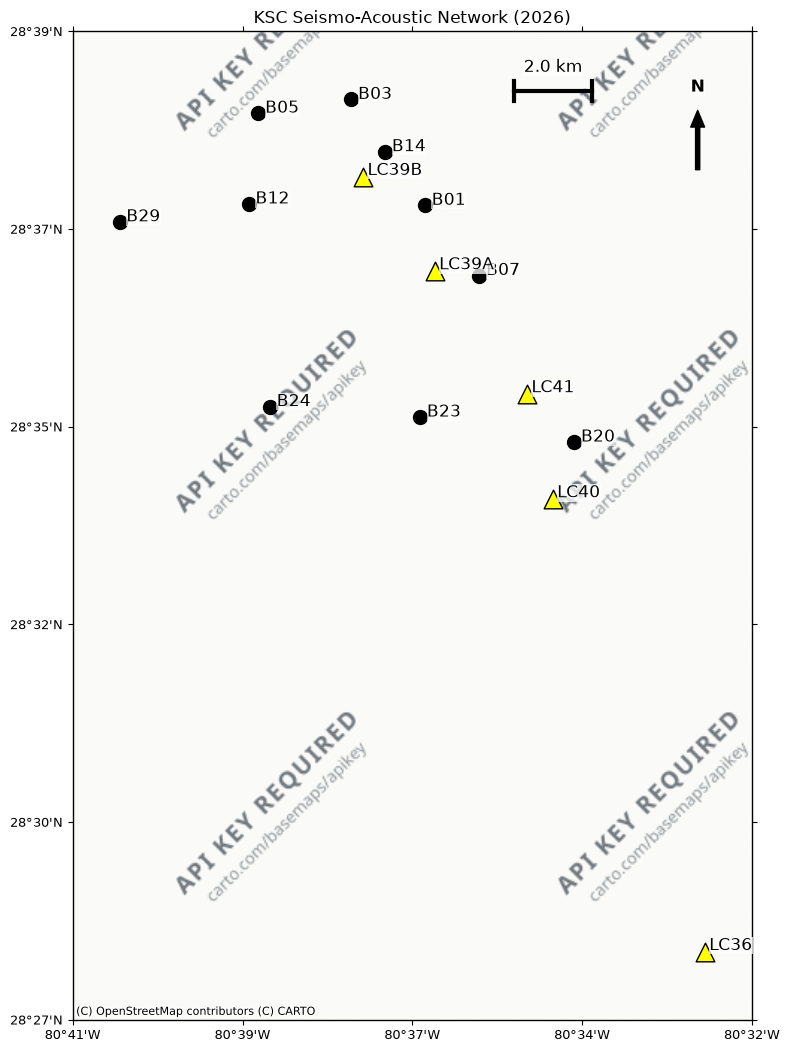

In [14]:
import sys
import os
from pathlib import Path
import contextily as cx

print(os.getcwd())

from station_map import plot_station_map_tiles, save_figures

excelfile = STATION_XLS

fig, ax, gdf = plot_station_map_tiles(
    excelfile,
    sheet_name="artemis2",
    launchpad_sheet="launchpads_2026",
    marker_size=100,
    marker_color="black",
    marker_edgecolor="black",
    label_size=12,
    label_color="black",
    label_dx_frac=0.010,
    label_dy_frac=0.005,
    basemap=cx.providers.CartoDB.Positron,
    group_clusters=True,
    cluster_frac_x=0.02,
    cluster_frac_y=0.02,
    grouped_name_mode="join",
    add_scalebar=True,
    scalebar_location=(0.65, 0.94),
    scalebar_color="black",
    scalebar_fontsize=12,
    scalebar_linewidth=3,
    add_north_arrow=True,
    north_arrow_color="black",
    north_arrow_linewidth=3,
    north_arrow_fontsize=12,
    add_latlon_ticks=True,
    launchpad_size=180,
    launchpad_color="yellow",
    launchpad_edgecolor="black",
    launchpad_marker="^",
    add_launchpad_labels=True,
    launchpad_label_size=12,
    launchpad_label_color="black",
    title="KSC Seismo-Acoustic Network (2026)",
)

save_figures(
    fig,
    outdir=OUT_DIR,
    outfilebase="ksc_map_2026_simple",
    formats=["png", "pdf"],
)

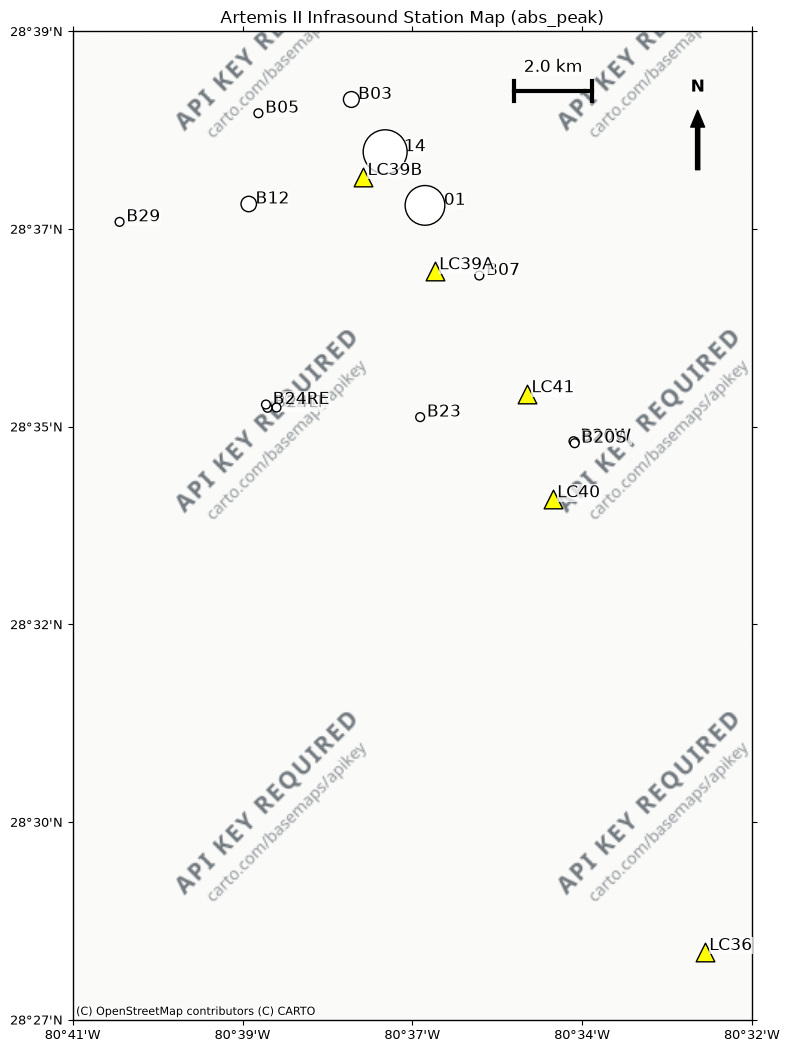

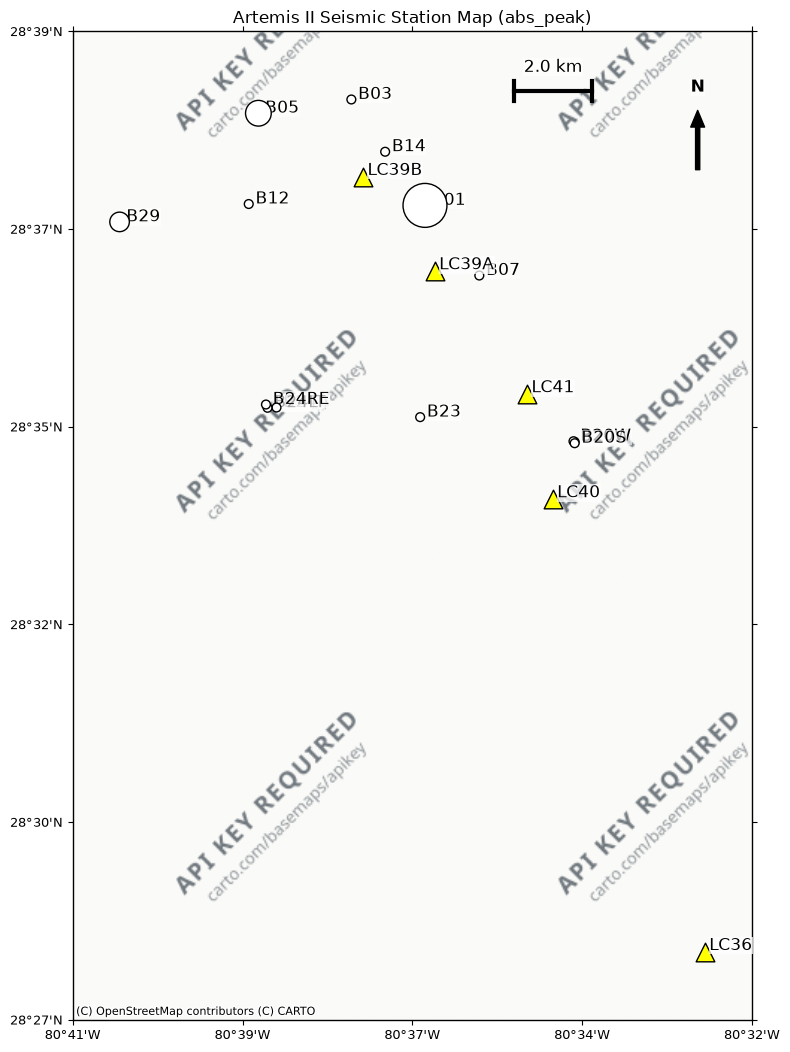

,station,abs_peak_station,marker_size_scaled
5,B14,1711.693244,1000.000000
0,B01,1547.294349,817.135362
1,B03,616.899932,129.890555
4,B12,601.920003,123.658985
2,B05,332.115352,40.000000
3,B07,327.395769,40.000000
9,B29,122.061288,40.000000
10,B24LT,104.638307,40.000000
11,B24RE,97.983565,40.000000
8,B24,87.316093,40.000000


,station,abs_peak_station,marker_size_scaled
0,B01,0.002931,1000.000000
2,B05,0.001716,342.597395
9,B29,0.001304,197.839708
1,B03,0.000073,40.000000
3,B07,NaN,40.000000
4,B12,NaN,40.000000
5,B14,NaN,40.000000
6,B20,NaN,40.000000
7,B23,NaN,40.000000
8,B24,NaN,40.000000


In [15]:
import numpy as np
import pandas as pd


def scale_symbol_sizes(
    values,
    *,
    mode="area",
    max_size=300.0,
    min_size=20.0,
    reference=None,
    clip_negative=True,
):
    """
    Scale marker sizes from amplitudes for use in matplotlib/geopandas.

    Parameters
    ----------
    values : array-like
        Amplitude values to convert into marker sizes.
    mode : {"area", "radius"}
        - "area": circle area is proportional to amplitude
        - "radius": circle radius is proportional to amplitude
    max_size : float
        Maximum marker size passed to matplotlib/geopandas for the
        largest amplitude. This is an area-like size parameter.
    min_size : float
        Minimum marker size for nonzero values.
    reference : float or None
        Reference amplitude corresponding to max_size.
        If None, uses the maximum finite value in `values`.
    clip_negative : bool
        If True, negative values are converted to absolute values.

    Returns
    -------
    sizes : np.ndarray
        Marker sizes suitable for matplotlib scatter/geopandas plot.
    """
    vals = np.asarray(values, dtype=float)

    if clip_negative:
        vals = np.abs(vals)

    vals[~np.isfinite(vals)] = np.nan

    if reference is None:
        if np.all(np.isnan(vals)):
            return np.full_like(vals, min_size, dtype=float)
        reference = np.nanmax(vals)

    if not np.isfinite(reference) or reference <= 0:
        return np.full_like(vals, min_size, dtype=float)

    ratio = vals / reference
    ratio = np.clip(ratio, 0.0, None)

    if mode == "area":
        # area proportional to amplitude
        sizes = max_size * ratio
    elif mode == "radius":
        # radius proportional to amplitude -> plotted size must scale as r^2
        sizes = max_size * ratio**2
    else:
        raise ValueError("mode must be 'area' or 'radius'")

    # keep zeros/very small values visible if desired
    sizes = np.where(np.isnan(sizes), min_size, sizes)
    sizes = np.where((ratio > 0) & (sizes < min_size), min_size, sizes)

    return sizes

# --- Single notebook cell: build sized station maps for infrasound and seismic ---

from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import contextily as cx
import matplotlib.pyplot as plt

# --------------------------------------------------------------------------
# User settings
# --------------------------------------------------------------------------
excelfile = STATION_XLS

# Where your amplitude CSVs were written earlier
amp_dir = OUT_DIR

# Choose which metric column to map
INFRA_COL = "abs_peak"   # alternatives: "rms", "abs_peak", "mean_abs"
SEIS_COL  = "abs_peak"      # alternatives: "abs_peak", "mean_abs", "std", 'RMS

# Symbol sizing options
SIZE_MODE = "radius"     # "area" or "radius"
MAX_MARKER_SIZE = 1000  # matplotlib/geopandas marker size for largest value
MIN_MARKER_SIZE = 40   # minimum visible symbol size

# --------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------
def seed_id_to_station(seed_id: str) -> str:
    """
    Convert SEED id NET.STA.LOC.CHA to station code STA.
    """
    parts = str(seed_id).split(".")
    return parts[1] if len(parts) > 1 else str(seed_id)


def scale_symbol_sizes(
    values,
    *,
    mode="area",
    max_size=300.0,
    min_size=20.0,
    reference=None,
    clip_negative=True,
):
    """
    Convert amplitudes into matplotlib/geopandas marker sizes.

    Parameters
    ----------
    values : array-like
        Amplitudes or metrics to scale.
    mode : {"area", "radius"}
        "area"   -> plotted circle area proportional to amplitude
        "radius" -> plotted circle radius proportional to amplitude
    max_size : float
        Marker size used for the largest amplitude.
    min_size : float
        Minimum marker size for nonzero finite values.
    reference : float or None
        Reference amplitude corresponding to max_size.
        If None, uses max(values).
    clip_negative : bool
        If True, uses abs(values).

    Returns
    -------
    np.ndarray
        Marker sizes suitable for matplotlib scatter / geopandas plot.
    """
    vals = np.asarray(values, dtype=float)

    if clip_negative:
        vals = np.abs(vals)

    vals[~np.isfinite(vals)] = np.nan

    if reference is None:
        if np.all(np.isnan(vals)):
            return np.full_like(vals, min_size, dtype=float)
        reference = np.nanmax(vals)

    if not np.isfinite(reference) or reference <= 0:
        return np.full_like(vals, min_size, dtype=float)

    ratio = vals / reference
    ratio = np.clip(ratio, 0.0, None)

    if mode == "area":
        sizes = max_size * ratio
    elif mode == "radius":
        sizes = max_size * ratio**2
    else:
        raise ValueError("mode must be 'area' or 'radius'")

    sizes = np.where(np.isnan(sizes), min_size, sizes)
    sizes = np.where((ratio > 0) & (sizes < min_size), min_size, sizes)
    return sizes


# --------------------------------------------------------------------------
# Load amplitude tables
# --------------------------------------------------------------------------
infra_csv = amp_dir / "peak_infrasound_amplitudes.csv"
seis_csv  = amp_dir / "peak_seismic_amplitudes.csv"

df_infra = pd.read_csv(infra_csv)
df_seis  = pd.read_csv(seis_csv)

df_infra["station"] = df_infra["SEED_id"].apply(seed_id_to_station)
df_seis["station"]  = df_seis["SEED_id"].apply(seed_id_to_station)

# --------------------------------------------------------------------------
# Reduce to one value per station
# (Change .max() to .mean() or another reducer if you prefer.)
# --------------------------------------------------------------------------
station_infra = (
    df_infra.groupby("station", as_index=False)[INFRA_COL]
    .max()
    .rename(columns={INFRA_COL: f"{INFRA_COL}_station"})
)

station_seis = (
    df_seis.groupby("station", as_index=False)[SEIS_COL]
    .max()
    .rename(columns={SEIS_COL: f"{SEIS_COL}_station"})
)

# --------------------------------------------------------------------------
# Load station coordinates from spreadsheet and merge metrics
# --------------------------------------------------------------------------
stations = pd.read_excel(excelfile, sheet_name="artemis2")

stations_infra = stations.merge(station_infra, on="station", how="left")
stations_seis  = stations.merge(station_seis,  on="station", how="left")

# --------------------------------------------------------------------------
# Compute marker sizes
# --------------------------------------------------------------------------
stations_infra["marker_size_scaled"] = scale_symbol_sizes(
    stations_infra[f"{INFRA_COL}_station"],
    mode=SIZE_MODE,
    max_size=MAX_MARKER_SIZE,
    min_size=MIN_MARKER_SIZE,
)

stations_seis["marker_size_scaled"] = scale_symbol_sizes(
    stations_seis[f"{SEIS_COL}_station"],
    mode=SIZE_MODE,
    max_size=MAX_MARKER_SIZE,
    min_size=MIN_MARKER_SIZE,
)

# --------------------------------------------------------------------------
# Plotting helper
# Uses your existing plot_station_map_tiles(), then overlays scaled circles.
# --------------------------------------------------------------------------
def make_scaled_station_map(
    station_df,
    *,
    title,
    excelfile=excelfile,
    station_sheet="artemis2",
    launchpad_sheet="launchpads_2026",
    marker_color="white",
    marker_edgecolor="black",
    label_size=12,
    label_color="black",
    label_dx_frac=0.010,
    label_dy_frac=0.005,
    basemap=cx.providers.CartoDB.Positron,
    launchpad_size=180,
    launchpad_color="yellow",
    launchpad_edgecolor="black",
    launchpad_marker="^",
):
    # Base map comes from the Excel workbook so launchpad_sheet can be read properly
    fig, ax, gdf_plot = plot_station_map_tiles(
        excelfile,
        sheet_name=station_sheet,
        launchpad_sheet=launchpad_sheet,
        marker_size=1,
        marker_color="white",
        marker_edgecolor="black",
        label_size=label_size,
        label_color=label_color,
        label_dx_frac=label_dx_frac,
        label_dy_frac=label_dy_frac,
        basemap=basemap,
        group_clusters=False,
        add_scalebar=True,
        scalebar_location=(0.65, 0.94),
        scalebar_color="black",
        scalebar_fontsize=12,
        scalebar_linewidth=3,
        add_north_arrow=True,
        north_arrow_color="black",
        north_arrow_linewidth=3,
        north_arrow_fontsize=12,
        add_latlon_ticks=True,
        launchpad_size=launchpad_size,
        launchpad_color=launchpad_color,
        launchpad_edgecolor=launchpad_edgecolor,
        launchpad_marker=launchpad_marker,
        add_launchpad_labels=True,
        launchpad_label_size=12,
        launchpad_label_color="black",
        title=title,
    )

    # Overlay scaled circles from the merged station dataframe
    gdf_scaled = gpd.GeoDataFrame(
        station_df.copy(),
        geometry=gpd.points_from_xy(station_df["lon"], station_df["lat"]),
        crs="EPSG:4326",
    ).to_crs(epsg=3857)

    ax.scatter(
        gdf_scaled.geometry.x,
        gdf_scaled.geometry.y,
        s=station_df["marker_size_scaled"].to_numpy(),
        c=marker_color,
        edgecolors=marker_edgecolor,
        zorder=7,
    )

    return fig, ax, gdf_scaled


# --------------------------------------------------------------------------
# Make the two maps
# --------------------------------------------------------------------------
fig_infra, ax_infra, gdf_infra = make_scaled_station_map(
    stations_infra,
    title=f"Artemis II Infrasound Station Map ({INFRA_COL})",
)

fig_seis, ax_seis, gdf_seis = make_scaled_station_map(
    stations_seis,
    title=f"Artemis II Seismic Station Map ({SEIS_COL})",
)

# --------------------------------------------------------------------------
# Save
# --------------------------------------------------------------------------
fig_infra.savefig(OUT_DIR / f"artemis2_infrasound_map_{INFRA_COL}.png", dpi=300, bbox_inches="tight")
fig_infra.savefig(OUT_DIR / f"artemis2_infrasound_map_{INFRA_COL}.pdf", dpi=300, bbox_inches="tight")

fig_seis.savefig(OUT_DIR / f"artemis2_seismic_map_{SEIS_COL}.png", dpi=300, bbox_inches="tight")
fig_seis.savefig(OUT_DIR / f"artemis2_seismic_map_{SEIS_COL}.pdf", dpi=300, bbox_inches="tight")

plt.show()

# Optional: inspect the merged tables
display(stations_infra[["station", INFRA_COL + "_station", "marker_size_scaled"]].sort_values(INFRA_COL + "_station", ascending=False))
display(stations_seis[["station", SEIS_COL + "_station", "marker_size_scaled"]].sort_values(SEIS_COL + "_station", ascending=False))

LC39B: lat=28.627220, lon=-80.620830


,station,lat,lon,distance_km,rms_station
5,B14,28.632222,-80.615833,0.739735,1337.164297
0,B01,28.621389,-80.606667,1.526912,1389.701845
1,B03,28.642778,-80.623611,1.751109,419.978085
4,B12,28.621667,-80.647222,2.648979,428.278640
2,B05,28.640000,-80.645000,2.753876,104.568110
3,B07,28.607222,-80.594167,3.423210,174.914540
8,B24,28.580556,-80.640833,5.544148,27.723473
7,B23,28.578611,-80.607778,5.553226,30.508279
11,B24RE,28.581160,-80.643260,5.570092,25.686814
9,B29,28.618056,-80.676944,5.571110,32.461787


,station,lat,lon,distance_km,rms_station
5,B14,28.632222,-80.615833,0.739735,NaN
0,B01,28.621389,-80.606667,1.526912,0.000925
1,B03,28.642778,-80.623611,1.751109,0.000015
4,B12,28.621667,-80.647222,2.648979,NaN
2,B05,28.640000,-80.645000,2.753876,0.000350
3,B07,28.607222,-80.594167,3.423210,NaN
8,B24,28.580556,-80.640833,5.544148,NaN
7,B23,28.578611,-80.607778,5.553226,NaN
11,B24RE,28.581160,-80.643260,5.570092,NaN
9,B29,28.618056,-80.676944,5.571110,0.000481


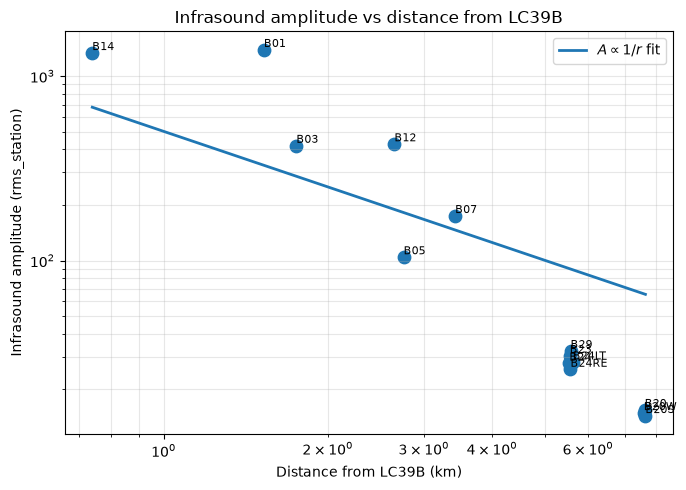

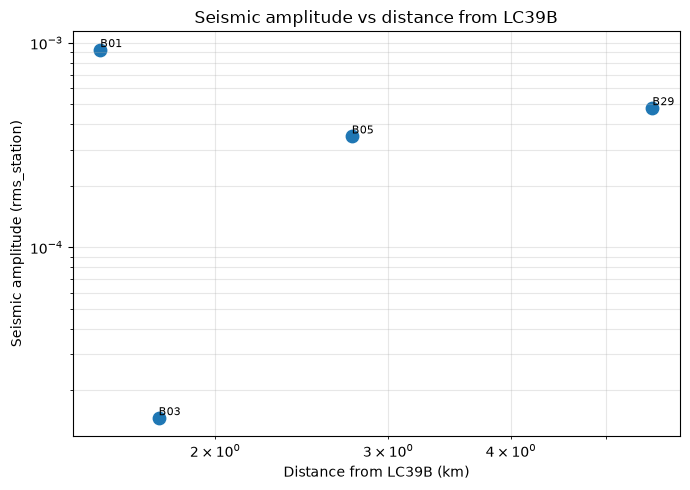

In [16]:
# --- Amplitude vs distance from LC39B ---

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------------------------------
# User settings
# --------------------------------------------------------------------------
excelfile = STATION_XLS

station_sheet = "artemis2"
launchpad_sheet = "launchpads_2026"
launchpad_name = "LC39B"   # must match the 'pad' column in the launchpad sheet

# Which metric columns to plot
INFRA_COL = "rms_station"      # try: "rms_station", "abs_peak_station", "spl_db_station"
SEIS_COL  = "rms_station"      # try: "rms_station", "abs_peak_station"

# --------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------
def haversine_km(lon1, lat1, lon2, lat2):
    """
    Great-circle distance in km.
    """
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6371.0 * c  # Earth radius in km


def seed_id_to_station(seed_id: str) -> str:
    parts = str(seed_id).split(".")
    return parts[1] if len(parts) > 1 else str(seed_id)


def fit_k_over_r(distance_km, amplitude):
    """
    Fit A = k/r in least-squares sense with k = mean(A*r) weighted by available data.
    """
    r = np.asarray(distance_km, dtype=float)
    a = np.asarray(amplitude, dtype=float)
    mask = np.isfinite(r) & np.isfinite(a) & (r > 0) & (a > 0)
    if not np.any(mask):
        return np.nan
    r = r[mask]
    a = a[mask]
    # Least squares fit for a = k / r  -> k ~ average(a*r)
    return np.mean(a * r)


# --------------------------------------------------------------------------
# Load amplitude tables and reduce to one value per station
# --------------------------------------------------------------------------
amp_dir = OUT_DIR

df_infra = pd.read_csv(amp_dir / "peak_infrasound_amplitudes.csv")
df_seis  = pd.read_csv(amp_dir / "peak_seismic_amplitudes.csv")

df_infra["station"] = df_infra["SEED_id"].apply(seed_id_to_station)
df_seis["station"]  = df_seis["SEED_id"].apply(seed_id_to_station)

station_infra = (
    df_infra.groupby("station", as_index=False)[INFRA_COL.replace("_station", "")]
    .max()
    .rename(columns={INFRA_COL.replace("_station", ""): INFRA_COL})
)

station_seis = (
    df_seis.groupby("station", as_index=False)[SEIS_COL.replace("_station", "")]
    .max()
    .rename(columns={SEIS_COL.replace("_station", ""): SEIS_COL})
)

# --------------------------------------------------------------------------
# Load station coordinates and launchpad coordinates from Excel
# --------------------------------------------------------------------------
stations = pd.read_excel(excelfile, sheet_name=station_sheet)
pads = pd.read_excel(excelfile, sheet_name=launchpad_sheet)

# Standardize expected column names
stations = stations.rename(columns={"lat": "lat", "lon": "lon", "station": "station"}).copy()
pads = pads.rename(columns={"pad": "pad", "lat": "lat", "lon": "lon"}).copy()

# Find LC39B
pad_row = pads.loc[pads["pad"].astype(str).str.upper() == launchpad_name.upper()]
if pad_row.empty:
    raise ValueError(f"Launchpad '{launchpad_name}' not found in sheet '{launchpad_sheet}'")

pad_lat = float(pad_row.iloc[0]["lat"])
pad_lon = float(pad_row.iloc[0]["lon"])

print(f"{launchpad_name}: lat={pad_lat:.6f}, lon={pad_lon:.6f}")

# Compute distances from LC39B
stations = stations.copy()
stations["distance_km"] = haversine_km(
    stations["lon"].astype(float).to_numpy(),
    stations["lat"].astype(float).to_numpy(),
    pad_lon,
    pad_lat,
)

# Merge with amplitudes
infra_dist = stations.merge(station_infra, on="station", how="left")
seis_dist  = stations.merge(station_seis,  on="station", how="left")

display(infra_dist[["station", "lat", "lon", "distance_km", INFRA_COL]].sort_values("distance_km"))
display(seis_dist[["station", "lat", "lon", "distance_km", SEIS_COL]].sort_values("distance_km"))

# --------------------------------------------------------------------------
# Plot 1: Infrasound amplitude vs distance with A ~ k/r reference line
# --------------------------------------------------------------------------
plot_infra = infra_dist.dropna(subset=[INFRA_COL, "distance_km"]).copy()
plot_infra = plot_infra[(plot_infra["distance_km"] > 0) & (plot_infra[INFRA_COL] > 0)].copy()

k_infra = fit_k_over_r(plot_infra["distance_km"], plot_infra[INFRA_COL])

r_fit = np.linspace(plot_infra["distance_km"].min(), plot_infra["distance_km"].max(), 200)
a_fit = k_infra / r_fit

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(plot_infra["distance_km"], plot_infra[INFRA_COL], s=80)

for _, row in plot_infra.iterrows():
    ax.text(row["distance_km"], row[INFRA_COL], str(row["station"]), fontsize=8, ha="left", va="bottom")

ax.plot(r_fit, a_fit, linewidth=2, label=r"$A \propto 1/r$ fit")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(f"Distance from {launchpad_name} (km)")
ax.set_ylabel(f"Infrasound amplitude ({INFRA_COL})")
ax.set_title(f"Infrasound amplitude vs distance from {launchpad_name}")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(OUT_DIR / f"infrasound_{INFRA_COL}_vs_distance_{launchpad_name}.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / f"infrasound_{INFRA_COL}_vs_distance_{launchpad_name}.pdf", dpi=300, bbox_inches="tight")


# --------------------------------------------------------------------------
# Plot 2: Seismic amplitude vs distance
# --------------------------------------------------------------------------
plot_seis = seis_dist.dropna(subset=[SEIS_COL, "distance_km"]).copy()
plot_seis = plot_seis[(plot_seis["distance_km"] > 0) & (plot_seis[SEIS_COL] > 0)].copy()

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(plot_seis["distance_km"], plot_seis[SEIS_COL], s=80)

for _, row in plot_seis.iterrows():
    ax.text(row["distance_km"], row[SEIS_COL], str(row["station"]), fontsize=8, ha="left", va="bottom")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(f"Distance from {launchpad_name} (km)")
ax.set_ylabel(f"Seismic amplitude ({SEIS_COL})")
ax.set_title(f"Seismic amplitude vs distance from {launchpad_name}")
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()

fig.savefig(OUT_DIR / f"seismic_{SEIS_COL}_vs_distance_{launchpad_name}.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / f"seismic_{SEIS_COL}_vs_distance_{launchpad_name}.pdf", dpi=300, bbox_inches="tight")

plt.show()

LC39B: lat=28.627220, lon=-80.620830


,SEED_id,station,channel,distance_km,rms
0,1R.B14..HDF,B14,HDF,0.739735,1337.164297
2,1R.B14..HDI,B14,HDI,0.739735,1045.560129
1,1R.B01..HDI,B01,HDI,1.526912,1389.701845
5,1R.B01.00.DD0,B01,DD0,1.526912,131.702937
6,1R.B01.00.DD1,B01,DD1,1.526912,124.901524
7,1R.B01.00.DD2,B01,DD2,1.526912,120.554549
3,1R.B03..HDI,B03,HDI,1.751109,419.978085
23,1R.B03.00.DD0,B03,DD0,1.751109,0.201801
4,1R.B12..HDF,B12,HDF,2.648979,428.278640
8,1R.B05.00.DD0,B05,DD0,2.753876,104.568110


,SEED_id,station,channel,distance_km,rms
2,1R.B01.00.DH1,B01,DH1,1.526912,0.000683
1,1R.B01.00.DH2,B01,DH2,1.526912,0.000779
0,1R.B01.00.DHZ,B01,DHZ,1.526912,0.000925
8,1R.B03.00.DH1,B03,DH1,1.751109,0.000013
11,1R.B03.00.DH2,B03,DH2,1.751109,0.000004
9,1R.B03.00.DHZ,B03,DHZ,1.751109,0.000015
6,1R.B05.00.DH1,B05,DH1,2.753876,0.000350
10,1R.B05.00.DH2,B05,DH2,2.753876,0.000007
3,1R.B05.00.DHZ,B05,DHZ,2.753876,0.000288
7,1R.B29.00.DH1,B29,DH1,5.571110,0.000242


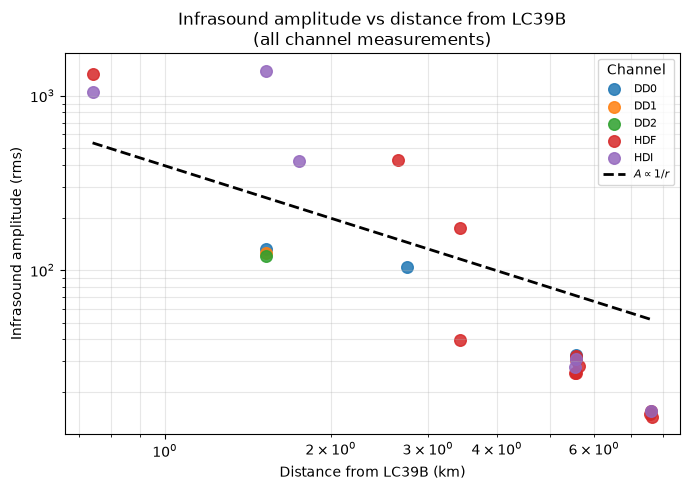

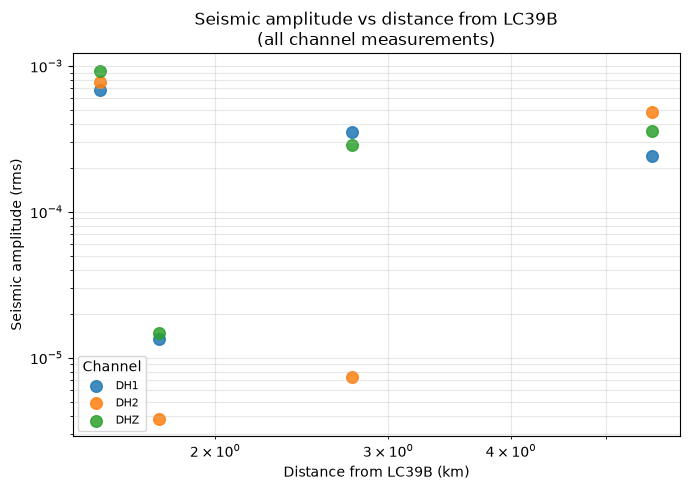

In [17]:
# --- Amplitude vs distance from LC39B, using every channel measurement ---

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------------------------------
# User settings
# --------------------------------------------------------------------------
excelfile = STATION_XLS

station_sheet = "artemis2"
launchpad_sheet = "launchpads_2026"
launchpad_name = "LC39B"   # must match the 'pad' column in the launchpad sheet

# Choose which metric columns to plot
INFRA_COL = "rms"      # try: "rms", "abs_peak", "mean_abs", "spl_db"
SEIS_COL  = "rms"      # try: "rms", "abs_peak", "mean_abs", "std"

# Label points? Can get messy if True
LABEL_POINTS = False
LABEL_COLUMN = "SEED_id"   # "SEED_id", "station", or "channel"

# Add simple 1/r reference fit to infrasound
ADD_1_OVER_R_FIT = True

# --------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------
def haversine_km(lon1, lat1, lon2, lat2):
    """
    Great-circle distance in km.
    """
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6371.0 * c


def seed_id_to_station(seed_id: str) -> str:
    parts = str(seed_id).split(".")
    return parts[1] if len(parts) > 1 else str(seed_id)


def seed_id_to_channel(seed_id: str) -> str:
    parts = str(seed_id).split(".")
    return parts[3] if len(parts) > 3 else ""


def fit_k_over_r(distance_km, amplitude):
    """
    Fit A = k/r in a simple least-squares sense using k ~ mean(A*r).
    """
    r = np.asarray(distance_km, dtype=float)
    a = np.asarray(amplitude, dtype=float)
    mask = np.isfinite(r) & np.isfinite(a) & (r > 0) & (a > 0)
    if not np.any(mask):
        return np.nan
    r = r[mask]
    a = a[mask]
    return np.mean(a * r)


# --------------------------------------------------------------------------
# Load channel-level amplitude tables
# --------------------------------------------------------------------------
amp_dir = OUT_DIR

df_infra = pd.read_csv(amp_dir / "peak_infrasound_amplitudes.csv")
df_seis  = pd.read_csv(amp_dir / "peak_seismic_amplitudes.csv")

# Extract station and channel from SEED id
for df_ in [df_infra, df_seis]:
    df_["station"] = df_["SEED_id"].apply(seed_id_to_station)
    df_["channel"] = df_["SEED_id"].apply(seed_id_to_channel)

# --------------------------------------------------------------------------
# Load station coordinates and launchpad coordinates from Excel
# --------------------------------------------------------------------------
stations = pd.read_excel(excelfile, sheet_name=station_sheet)
pads = pd.read_excel(excelfile, sheet_name=launchpad_sheet)

stations = stations.rename(columns={"station": "station", "lat": "lat", "lon": "lon"}).copy()
pads = pads.rename(columns={"pad": "pad", "lat": "lat", "lon": "lon"}).copy()

pad_row = pads.loc[pads["pad"].astype(str).str.upper() == launchpad_name.upper()]
if pad_row.empty:
    raise ValueError(f"Launchpad '{launchpad_name}' not found in sheet '{launchpad_sheet}'")

pad_lat = float(pad_row.iloc[0]["lat"])
pad_lon = float(pad_row.iloc[0]["lon"])

print(f"{launchpad_name}: lat={pad_lat:.6f}, lon={pad_lon:.6f}")

# Compute distance from launchpad for each station
stations = stations.copy()
stations["distance_km"] = haversine_km(
    stations["lon"].astype(float).to_numpy(),
    stations["lat"].astype(float).to_numpy(),
    pad_lon,
    pad_lat,
)

# Merge station coordinates onto every channel-level measurement
infra_dist = df_infra.merge(
    stations[["station", "lat", "lon", "distance_km"]],
    on="station",
    how="left",
)

seis_dist = df_seis.merge(
    stations[["station", "lat", "lon", "distance_km"]],
    on="station",
    how="left",
)

# Choose label column
for df_ in [infra_dist, seis_dist]:
    if LABEL_COLUMN not in df_.columns:
        df_["label"] = df_["SEED_id"]
    else:
        df_["label"] = df_[LABEL_COLUMN]

# Inspect merged tables
display(
    infra_dist[["SEED_id", "station", "channel", "distance_km", INFRA_COL]]
    .sort_values(["distance_km", "SEED_id"])
)

display(
    seis_dist[["SEED_id", "station", "channel", "distance_km", SEIS_COL]]
    .sort_values(["distance_km", "SEED_id"])
)

# --------------------------------------------------------------------------
# Plot 1: Infrasound amplitude vs distance, all channel measurements
# --------------------------------------------------------------------------
plot_infra = infra_dist.dropna(subset=[INFRA_COL, "distance_km"]).copy()
# Example: drop a specific SEED id
BAD_CHANNELS = [
    "1R.B03.00.DD0",   # replace with your actual SEED_id
]

plot_infra = plot_infra[~plot_infra["SEED_id"].isin(BAD_CHANNELS)].copy()
plot_infra = plot_infra[
    np.isfinite(plot_infra["distance_km"]) &
    np.isfinite(plot_infra[INFRA_COL]) &
    (plot_infra["distance_km"] > 0)
].copy()

# For log y-axis, keep positive values only
if INFRA_COL != "spl_db":
    plot_infra = plot_infra[plot_infra[INFRA_COL] > 0].copy()

fig, ax = plt.subplots(figsize=(7, 5))

# Color by channel so repeated measurements at one station are easier to spot
channels_infra = sorted(plot_infra["channel"].dropna().unique())
cmap = plt.get_cmap("tab10")
channel_colors = {ch: cmap(i % 10) for i, ch in enumerate(channels_infra)}

for ch in channels_infra:
    sub = plot_infra[plot_infra["channel"] == ch]
    ax.scatter(
        sub["distance_km"],
        sub[INFRA_COL],
        s=70,
        label=ch,
        color=channel_colors[ch],
        alpha=0.85,
    )

if LABEL_POINTS:
    for _, row in plot_infra.iterrows():
        ax.text(
            row["distance_km"],
            row[INFRA_COL],
            str(row["label"]),
            fontsize=7,
            ha="left",
            va="bottom",
        )

# Add 1/r reference fit only if plotting linear amplitude, not dB
if ADD_1_OVER_R_FIT and INFRA_COL != "spl_db":
    k_infra = fit_k_over_r(plot_infra["distance_km"], plot_infra[INFRA_COL])
    if np.isfinite(k_infra):
        r_fit = np.linspace(plot_infra["distance_km"].min(), plot_infra["distance_km"].max(), 200)
        a_fit = k_infra / r_fit
        ax.plot(r_fit, a_fit, linewidth=2, color="black", linestyle="--", label=r"$A \propto 1/r$")

ax.set_xscale("log")
if INFRA_COL != "spl_db":
    ax.set_yscale("log")

ax.set_xlabel(f"Distance from {launchpad_name} (km)")
ax.set_ylabel(f"Infrasound amplitude ({INFRA_COL})")
ax.set_title(f"Infrasound amplitude vs distance from {launchpad_name}\n(all channel measurements)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(title="Channel", fontsize=8)
fig.tight_layout()

fig.savefig(OUT_DIR / f"infrasound_{INFRA_COL}_vs_distance_{launchpad_name}_all_channels_except_B03.DDO.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / f"infrasound_{INFRA_COL}_vs_distance_{launchpad_name}_all_channels_except_B03.DDO.pdf", dpi=300, bbox_inches="tight")

# --------------------------------------------------------------------------
# Plot 2: Seismic amplitude vs distance, all channel measurements
# --------------------------------------------------------------------------
plot_seis = seis_dist.dropna(subset=[SEIS_COL, "distance_km"]).copy()
plot_seis = plot_seis[
    np.isfinite(plot_seis["distance_km"]) &
    np.isfinite(plot_seis[SEIS_COL]) &
    (plot_seis["distance_km"] > 0) &
    (plot_seis[SEIS_COL] > 0)
].copy()

fig, ax = plt.subplots(figsize=(7, 5))

channels_seis = sorted(plot_seis["channel"].dropna().unique())
cmap = plt.get_cmap("tab10")
channel_colors = {ch: cmap(i % 10) for i, ch in enumerate(channels_seis)}

for ch in channels_seis:
    sub = plot_seis[plot_seis["channel"] == ch]
    ax.scatter(
        sub["distance_km"],
        sub[SEIS_COL],
        s=70,
        label=ch,
        color=channel_colors[ch],
        alpha=0.85,
    )

if LABEL_POINTS:
    for _, row in plot_seis.iterrows():
        ax.text(
            row["distance_km"],
            row[SEIS_COL],
            str(row["label"]),
            fontsize=7,
            ha="left",
            va="bottom",
        )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(f"Distance from {launchpad_name} (km)")
ax.set_ylabel(f"Seismic amplitude ({SEIS_COL})")
ax.set_title(f"Seismic amplitude vs distance from {launchpad_name}\n(all channel measurements)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(title="Channel", fontsize=8)
fig.tight_layout()

fig.savefig(OUT_DIR / f"seismic_{SEIS_COL}_vs_distance_{launchpad_name}_all_channels.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / f"seismic_{SEIS_COL}_vs_distance_{launchpad_name}_all_channels.pdf", dpi=300, bbox_inches="tight")

plt.show()

In [18]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------
# STEP 1: prepare data (assumes you already have this)
# ---------------------------------------------------------------------
# plot_infra must contain:
#   distance_km
#   INFRA_COL (e.g. "spl_db" or "rms")
#   SEED_id

df = plot_infra.copy()

# Remove invalid values
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["distance_km", INFRA_COL]).copy()
df = df[df["distance_km"] > 0].copy()

# ---------------------------------------------------------------------
# STEP 2: fit A = k / r in log space
# ---------------------------------------------------------------------
x = np.log10(df["distance_km"].values)
y = np.log10(df[INFRA_COL].values)

# Linear fit: y = a + b*x  (should be slope ≈ -1)
b, a = np.polyfit(x, y, 1)

print(f"Fit: log10(A) = {a:.3f} + {b:.3f} log10(r)")
print(f"Expected slope ~ -1 → got {b:.3f}")

# ---------------------------------------------------------------------
# STEP 3: predicted amplitudes
# ---------------------------------------------------------------------
y_pred = a + b * x
A_pred = 10**y_pred

df["A_pred"] = A_pred

# ---------------------------------------------------------------------
# STEP 4: anomaly metrics
# ---------------------------------------------------------------------

# (1) Ratio (most intuitive physically)
df["anomaly_ratio"] = df[INFRA_COL] / df["A_pred"]

# (2) Log residual (best for plotting)
df["anomaly_log10"] = np.log10(df["anomaly_ratio"])

# (3) dB anomaly (great for infrasound)
df["anomaly_db"] = 20 * df["anomaly_log10"]

# ---------------------------------------------------------------------
# STEP 5: rank channels by anomaly
# ---------------------------------------------------------------------
df = df.sort_values("anomaly_ratio", ascending=False)

display(df[[
    "SEED_id",
    "distance_km",
    INFRA_COL,
    "A_pred",
    "anomaly_ratio",
    "anomaly_db"
]].round(3))

Fit: log10(A) = 2.842 + -1.831 log10(r)
Expected slope ~ -1 → got -1.831


,SEED_id,distance_km,rms,A_pred,anomaly_ratio,anomaly_db
1,1R.B01..HDI,1.527,1389.702,320.030,4.342,12.755
4,1R.B12..HDF,2.649,428.279,116.677,3.671,11.295
9,1R.B07.10.HDF,3.423,174.915,72.953,2.398,7.596
3,1R.B03..HDI,1.751,419.978,249.012,1.687,4.540
0,1R.B14..HDF,0.740,1337.164,1206.767,1.108,0.891
10,1R.B29.00.DD0,5.571,32.462,29.900,1.086,0.714
13,1R.B29..HDF,5.571,32.150,29.900,1.075,0.630
15,1R.B29..HDI,5.571,31.013,29.900,1.037,0.318
17,1R.B23..HDF,5.553,30.508,30.077,1.014,0.124
8,1R.B05.00.DD0,2.754,104.568,108.667,0.962,-0.334


In [19]:
df_infra["win_start"] = pd.to_datetime(df_infra["win_start"], utc=True, errors="coerce")
launch_time_pd = pd.to_datetime(str(launchtime), utc=True)

df_infra["time_since_launch_s"] = (
    df_infra["win_start"] - launch_time_pd
).dt.total_seconds()

In [20]:
print(type(launchtime), launchtime)
print(df_infra["win_start"].iloc[0], type(df_infra["win_start"].iloc[0]))
print(launch_time_pd, type(launch_time_pd))

<class 'obspy.core.utcdatetime.UTCDateTime'> 2026-04-01T22:35:12.000000Z
2026-04-01 22:35:21.790000+00:00 <class 'pandas.Timestamp'>
2026-04-01 22:35:12+00:00 <class 'pandas.Timestamp'>


LC39B: lat=28.627220, lon=-80.620830


,SEED_id,station,channel,distance_km,win_start,time_since_launch_s
0,1R.B14..HDF,B14,HDF,0.739735,2026-04-01 22:35:21.790000+00:00,9.790
2,1R.B14..HDI,B14,HDI,0.739735,2026-04-01 22:35:29.270000+00:00,17.270
1,1R.B01..HDI,B01,HDI,1.526912,2026-04-01 22:35:39.450000+00:00,27.450
5,1R.B01.00.DD0,B01,DD0,1.526912,2026-04-01 22:35:33.712000+00:00,21.712
6,1R.B01.00.DD1,B01,DD1,1.526912,2026-04-01 22:35:33.714000+00:00,21.714
7,1R.B01.00.DD2,B01,DD2,1.526912,2026-04-01 22:35:33.714000+00:00,21.714
3,1R.B03..HDI,B03,HDI,1.751109,2026-04-01 22:35:33.360000+00:00,21.360
23,1R.B03.00.DD0,B03,DD0,1.751109,2026-04-01 22:35:17.272000+00:00,5.272
4,1R.B12..HDF,B12,HDF,2.648979,2026-04-01 22:35:39.350000+00:00,27.350
8,1R.B05.00.DD0,B05,DD0,2.753876,2026-04-01 22:35:20.436000+00:00,8.436


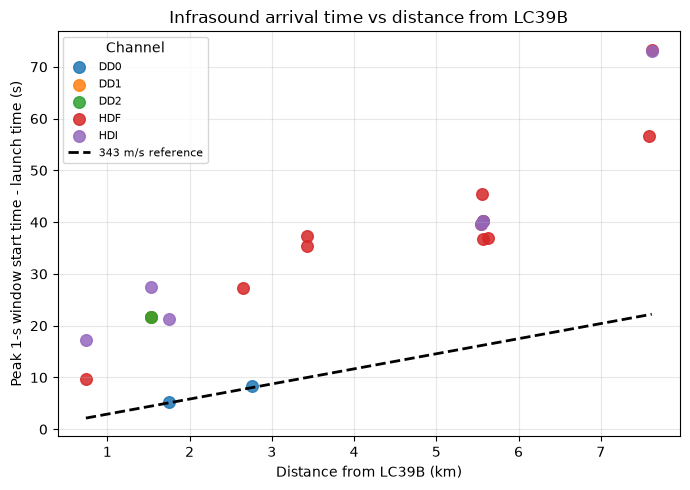

In [21]:
# --- Infrasound arrival time (win_start - launch_time) vs distance ---

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------------------------------
# User settings
# --------------------------------------------------------------------------
excelfile = STATION_XLS

station_sheet = "artemis2"
launchpad_sheet = "launchpads_2026"
launchpad_name = "LC39B"

# Set the launch time here
# Example:
launch_time = pd.Timestamp("2026-04-01T05:47:00Z")   # <-- replace with actual launch time

# Expected sound speed for reference line
c_sound = 343.0  # m/s

# Label points?
LABEL_POINTS = False
LABEL_COLUMN = "SEED_id"   # or "station", "channel"

# --------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------
def haversine_km(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6371.0 * c


def seed_id_to_station(seed_id: str) -> str:
    parts = str(seed_id).split(".")
    return parts[1] if len(parts) > 1 else str(seed_id)


def seed_id_to_channel(seed_id: str) -> str:
    parts = str(seed_id).split(".")
    return parts[3] if len(parts) > 3 else ""


# --------------------------------------------------------------------------
# Load channel-level metric tables
# --------------------------------------------------------------------------
amp_dir = OUT_DIR
infra_csv = amp_dir / "peak_infrasound_amplitudes.csv"
seis_csv  = amp_dir / "peak_seismic_amplitudes.csv"

df_infra = pd.read_csv(infra_csv)
df_seis  = pd.read_csv(seis_csv)

# Extract station and channel
df_infra["station"] = df_infra["SEED_id"].apply(seed_id_to_station)
df_infra["channel"] = df_infra["SEED_id"].apply(seed_id_to_channel)

df_infra["win_start"] = pd.to_datetime(df_infra["win_start"], utc=True, errors="coerce")
launch_time_pd = pd.to_datetime(str(launchtime), utc=True)

df_infra["time_since_launch_s"] = (
    df_infra["win_start"] - launch_time_pd
).dt.total_seconds()
'''
# Parse window start as datetime
df_infra["win_start"] = pd.to_datetime(df_infra["win_start"], utc=True, errors="coerce")

# Time since launch in seconds
df_infra["time_since_launch_s"] = (df_infra["win_start"] - launch_time).dt.total_seconds()
'''
# --------------------------------------------------------------------------
# Load station and launchpad coordinates from Excel
# --------------------------------------------------------------------------
stations = pd.read_excel(excelfile, sheet_name=station_sheet)
pads = pd.read_excel(excelfile, sheet_name=launchpad_sheet)

stations = stations.rename(columns={"station": "station", "lat": "lat", "lon": "lon"}).copy()
pads = pads.rename(columns={"pad": "pad", "lat": "lat", "lon": "lon"}).copy()

pad_row = pads.loc[pads["pad"].astype(str).str.upper() == launchpad_name.upper()]
if pad_row.empty:
    raise ValueError(f"Launchpad '{launchpad_name}' not found in sheet '{launchpad_sheet}'")

pad_lat = float(pad_row.iloc[0]["lat"])
pad_lon = float(pad_row.iloc[0]["lon"])

print(f"{launchpad_name}: lat={pad_lat:.6f}, lon={pad_lon:.6f}")

# Compute station distances to launchpad
stations = stations.copy()
stations["distance_km"] = haversine_km(
    stations["lon"].astype(float).to_numpy(),
    stations["lat"].astype(float).to_numpy(),
    pad_lon,
    pad_lat,
)

# Merge onto every infrasound channel record
infra_time = df_infra.merge(
    stations[["station", "lat", "lon", "distance_km"]],
    on="station",
    how="left",
)

if LABEL_COLUMN not in infra_time.columns:
    infra_time["label"] = infra_time["SEED_id"]
else:
    infra_time["label"] = infra_time[LABEL_COLUMN]

# Keep only valid rows
plot_df = infra_time.dropna(subset=["distance_km", "time_since_launch_s"]).copy()
plot_df = plot_df[np.isfinite(plot_df["distance_km"]) & np.isfinite(plot_df["time_since_launch_s"])].copy()
plot_df = plot_df[plot_df["distance_km"] > 0].copy()

display(
    plot_df[["SEED_id", "station", "channel", "distance_km", "win_start", "time_since_launch_s"]]
    .sort_values(["distance_km", "SEED_id"])
)

# --------------------------------------------------------------------------
# Plot: arrival time vs distance
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 5))

channels = sorted(plot_df["channel"].dropna().unique())
cmap = plt.get_cmap("tab10")
channel_colors = {ch: cmap(i % 10) for i, ch in enumerate(channels)}

for ch in channels:
    sub = plot_df[plot_df["channel"] == ch]
    ax.scatter(
        sub["distance_km"],
        sub["time_since_launch_s"],
        s=70,
        label=ch,
        color=channel_colors[ch],
        alpha=0.85,
    )

if LABEL_POINTS:
    for _, row in plot_df.iterrows():
        ax.text(
            row["distance_km"],
            row["time_since_launch_s"],
            str(row["label"]),
            fontsize=7,
            ha="left",
            va="bottom",
        )

# Reference line for constant sound speed
r_km = np.linspace(plot_df["distance_km"].min(), plot_df["distance_km"].max(), 200)
t_ref = (r_km * 1000.0) / c_sound
ax.plot(r_km, t_ref, "k--", linewidth=2, label=f"{c_sound:.0f} m/s reference")

ax.set_xlabel(f"Distance from {launchpad_name} (km)")
ax.set_ylabel("Peak 1-s window start time - launch time (s)")
ax.set_title(f"Infrasound arrival time vs distance from {launchpad_name}")
ax.grid(True, alpha=0.3)
ax.legend(title="Channel", fontsize=8)
fig.tight_layout()

fig.savefig(OUT_DIR / f"infrasound_arrival_time_vs_distance_{launchpad_name}.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT_DIR / f"infrasound_arrival_time_vs_distance_{launchpad_name}.pdf", dpi=300, bbox_inches="tight")

plt.show()


--- Linear fit ---
t = 6.84 + 0.006831 * r
Estimated propagation speed = 146.4 m/s

--- Quadratic fit ---
t = 17.73 + -0.000886 * r + 9.4336433090e-07 * r^2
Effective speed at mid-range ≈ 152.5 m/s


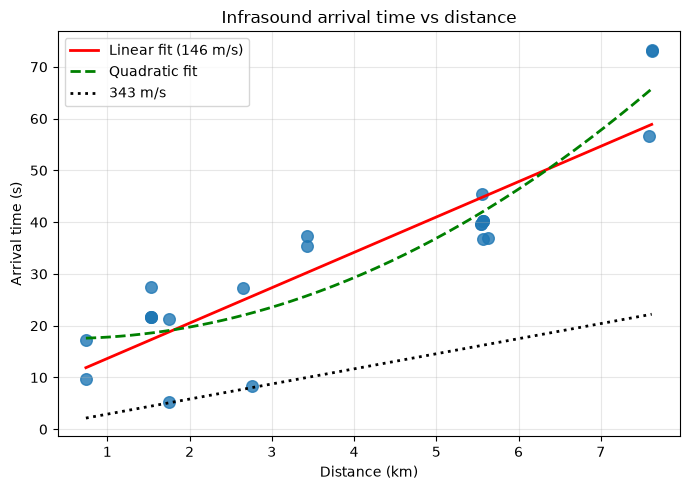

In [22]:
# --------------------------------------------------------------------------
# Fit arrival time vs distance
# --------------------------------------------------------------------------
import numpy as np

# Use clean data
fit_df = plot_df.copy()

# Independent variable: distance in meters
r = fit_df["distance_km"].values * 1000.0

# Dependent variable: time in seconds
t = fit_df["time_since_launch_s"].values

# Remove bad values
mask = np.isfinite(r) & np.isfinite(t) & (r > 0)
r = r[mask]
t = t[mask]

# --------------------------------------------------------------------------
# 1) LINEAR FIT: t = a + b r  → velocity = 1/b
# --------------------------------------------------------------------------
b, a = np.polyfit(r, t, 1)

velocity = 1.0 / b  # m/s

print("\n--- Linear fit ---")
print(f"t = {a:.2f} + {b:.6f} * r")
print(f"Estimated propagation speed = {velocity:.1f} m/s")

# --------------------------------------------------------------------------
# 2) QUADRATIC FIT: t = a + b r + c r^2
# --------------------------------------------------------------------------
c2, b2, a2 = np.polyfit(r, t, 2)

print("\n--- Quadratic fit ---")
print(f"t = {a2:.2f} + {b2:.6f} * r + {c2:.10e} * r^2")

# Effective "acceleration" interpretation
# If curvature exists, speed varies with distance:
# v(r) ≈ 1 / (b + 2 c r)

r_mid = np.mean(r)
v_mid = 1.0 / (b2 + 2 * c2 * r_mid)

print(f"Effective speed at mid-range ≈ {v_mid:.1f} m/s")

# --------------------------------------------------------------------------
# Plot everything
# --------------------------------------------------------------------------
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

# Scatter data
ax.scatter(plot_df["distance_km"], plot_df["time_since_launch_s"], s=70, alpha=0.8)

# Smooth distance axis
r_plot_km = np.linspace(plot_df["distance_km"].min(), plot_df["distance_km"].max(), 200)
r_plot_m = r_plot_km * 1000.0

# Linear fit curve
t_lin = a + b * r_plot_m
ax.plot(r_plot_km, t_lin, "r-", linewidth=2, label=f"Linear fit ({velocity:.0f} m/s)")

# Quadratic fit curve
t_quad = a2 + b2 * r_plot_m + c2 * r_plot_m**2
ax.plot(r_plot_km, t_quad, "g--", linewidth=2, label="Quadratic fit")

# Reference sound speed
c_sound = 343.0
t_ref = (r_plot_m) / c_sound
ax.plot(r_plot_km, t_ref, "k:", linewidth=2, label="343 m/s")

# Labels
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Arrival time (s)")
ax.set_title("Infrasound arrival time vs distance")

ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

,station,peak_time_s,peak_amplitude,peak_distance_m,peak_source_time_s,peak_phi_deg,peak_f_obs_hz,side,distance_km
0,W_00.5km,18.042775,0.001022,803.571684,15.7,36.014330,16.840170,West,0.803572
1,E_00.5km,19.713045,0.000944,861.974445,17.2,38.114593,16.636652,East,0.861974
2,W_01.0km,25.523829,0.000567,1551.673364,21.0,36.450306,15.878570,West,1.551673
3,E_01.0km,29.325427,0.000494,1723.721296,24.3,39.433899,15.436578,East,1.723721
4,W_01.5km,31.461265,0.000397,2284.813940,24.8,36.487615,15.206240,West,2.284814


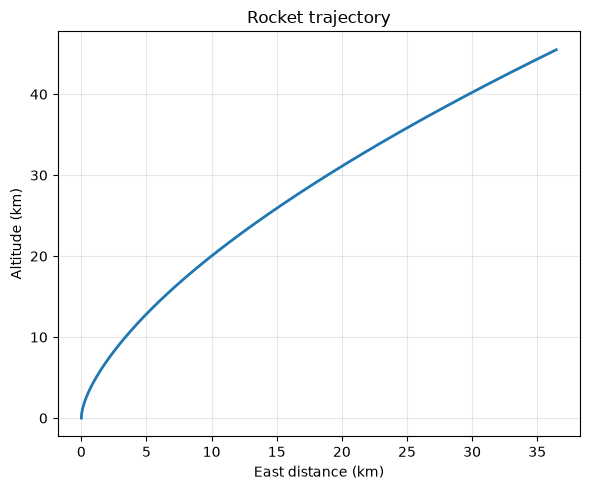

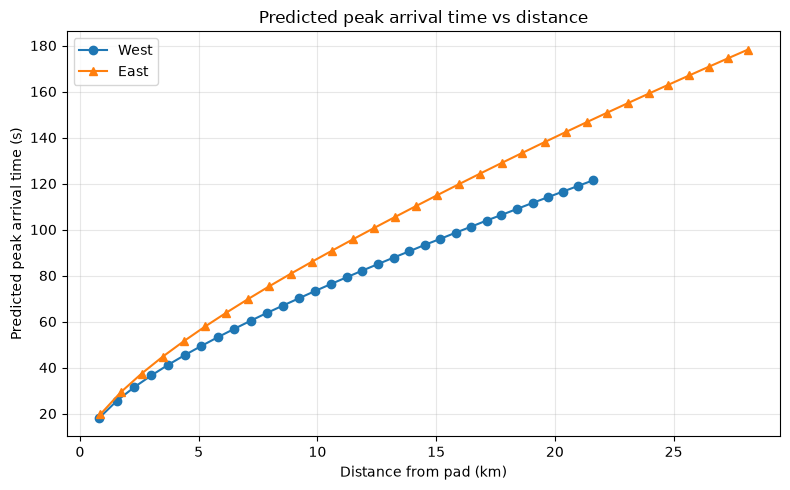

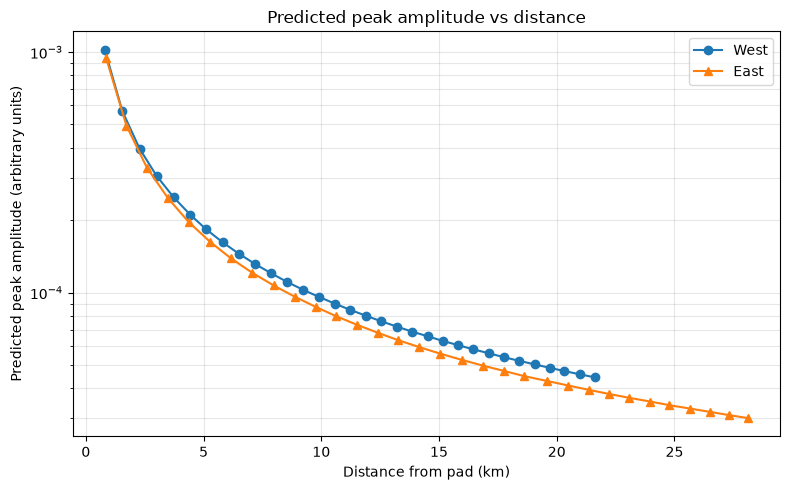

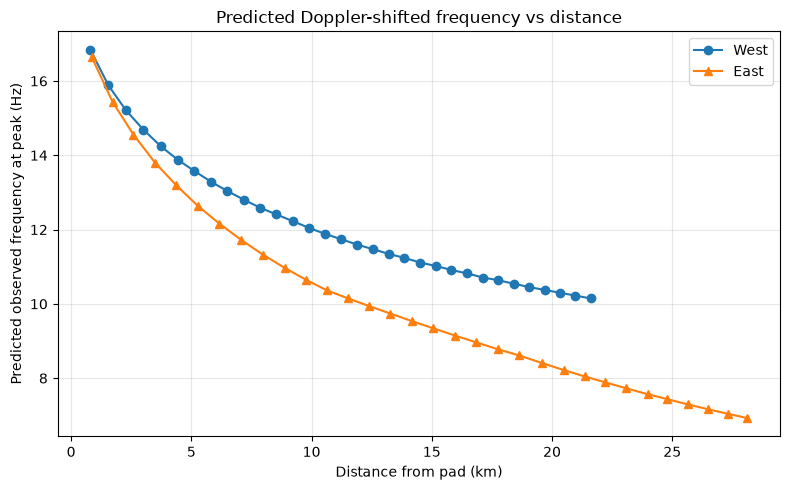

Saved synthetic_east_west_station_line_peak_metrics.csv


In [23]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Point this at wherever you unpacked the zip

from rocket_infrasound_model.model import RocketModel, Station
from rocket_infrasound_model.plotting import plot_trajectory, plot_network_peaks

# ------------------------------------------------------------------
# Build synthetic station line: west and east, every 0.5 km to 16 km
# ------------------------------------------------------------------
distances_km = np.arange(0.5, 16.0 + 0.001, 0.5)

stations = []
for d in distances_km:
    stations.append(Station(name=f"W_{d:04.1f}km", x_m=-1000.0 * d, z_m=0.0))
    stations.append(Station(name=f"E_{d:04.1f}km", x_m=+1000.0 * d, z_m=0.0))

# ------------------------------------------------------------------
# Define a simple rocket model
# ------------------------------------------------------------------
model = RocketModel(
    c_mps=343.0,      # sound speed
    q0=1.0,           # source strength scale
    phi0_deg=30.0,    # preferred radiation angle from exhaust axis
    sigma_deg=20.0,   # beam width
)

# ------------------------------------------------------------------
# Predict
# ------------------------------------------------------------------
result = model.predict_network(stations, t_max=120.0, dt=0.1)
peak_df = result.peak_metrics.copy()

# Add side and distance columns for easier plotting
peak_df["side"] = peak_df["station"].str[0].map({"W": "West", "E": "East"})
peak_df["distance_km"] = peak_df["peak_distance_m"] / 1000.0

display(peak_df.head())

# ------------------------------------------------------------------
# Plot 1: trajectory
# ------------------------------------------------------------------
fig, ax = plot_trajectory(model, t_max=120.0, dt=0.1)
plt.show()

# ------------------------------------------------------------------
# Plot 2: peak arrival time vs distance, east vs west
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))

for side, marker in [("West", "o"), ("East", "^")]:
    sub = peak_df[peak_df["side"] == side]
    ax.plot(
        sub["distance_km"],
        sub["peak_time_s"],
        marker=marker,
        linestyle="-",
        label=side,
    )

ax.set_xlabel("Distance from pad (km)")
ax.set_ylabel("Predicted peak arrival time (s)")
ax.set_title("Predicted peak arrival time vs distance")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

# ------------------------------------------------------------------
# Plot 3: peak amplitude vs distance, east vs west
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))

for side, marker in [("West", "o"), ("East", "^")]:
    sub = peak_df[peak_df["side"] == side]
    ax.plot(
        sub["distance_km"],
        sub["peak_amplitude"],
        marker=marker,
        linestyle="-",
        label=side,
    )

ax.set_xlabel("Distance from pad (km)")
ax.set_ylabel("Predicted peak amplitude (arbitrary units)")
ax.set_title("Predicted peak amplitude vs distance")
ax.set_yscale("log")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

# ------------------------------------------------------------------
# Plot 4: observed frequency at peak vs distance
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))

for side, marker in [("West", "o"), ("East", "^")]:
    sub = peak_df[peak_df["side"] == side]
    ax.plot(
        sub["distance_km"],
        sub["peak_f_obs_hz"],
        marker=marker,
        linestyle="-",
        label=side,
    )

ax.set_xlabel("Distance from pad (km)")
ax.set_ylabel("Predicted observed frequency at peak (Hz)")
ax.set_title("Predicted Doppler-shifted frequency vs distance")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

# ------------------------------------------------------------------
# Optional: save synthetic peak table
# ------------------------------------------------------------------
out_csv = Path("./synthetic_east_west_station_line_peak_metrics.csv")
peak_df.to_csv(out_csv, index=False)
print(f"Saved {out_csv}")

# 12. Create audio files

In [24]:
import numpy as np
from obspy import read
from scipy.io.wavfile import write as wavwrite
from scipy.signal import resample

def trace_to_audio(
    tr,
    speedup=100,
    output_wav="output.wav",
    audio_rate=44100,
    normalize=True,
    detrend=True,
    taper=True,
    bandpass=None,
):
    """
    Convert an ObsPy Trace to a WAV audio file by speeding it up.

    Parameters
    ----------
    tr : obspy.Trace
        Input seismic trace.
    speedup : float
        Factor by which to speed up playback.
    output_wav : str
        Output WAV filename.
    audio_rate : int
        Desired WAV sample rate in Hz.
    normalize : bool
        If True, scale data to int16 range.
    detrend : bool
        If True, remove mean and linear trend.
    taper : bool
        If True, apply a short taper.
    bandpass : tuple or None
        Optional (fmin, fmax) in Hz for pre-filtering the seismic data.
    """
    tr = tr.copy()

    if detrend:
        tr.detrend("linear")

    if taper:
        tr.taper(max_percentage=0.02)

    if bandpass is not None:
        fmin, fmax = bandpass
        tr.filter("bandpass", freqmin=fmin, freqmax=fmax, corners=4, zerophase=True)

    data = tr.data.astype(np.float64)

    # Remove NaNs/infs if present
    data = np.nan_to_num(data, nan=0.0, posinf=0.0, neginf=0.0)

    # Effective sampling rate after speeding up
    effective_rate = tr.stats.sampling_rate * speedup

    # Resample to desired audio rate if needed
    if abs(effective_rate - audio_rate) / audio_rate > 0.01:
        n_out = int(round(len(data) * audio_rate / effective_rate))
        if n_out <= 0:
            raise ValueError("Output sample count is invalid.")
        data = resample(data, n_out)

    if normalize:
        peak = np.max(np.abs(data))
        if peak > 0:
            data = data / peak
        data_int16 = np.int16(data * 32767)
    else:
        data_int16 = np.int16(np.clip(data, -32768, 32767))

    wavwrite(output_wav, audio_rate, data_int16)
    return output_wav


In [25]:

for tr in master_stream.copy().trim(starttime=starttrim, endtime=endtrim):
    output_wav = OUT_DIR / f'{tr.id}_audio.wav'
    trace_to_audio(tr, speedup=60, output_wav=str(output_wav), audio_rate=44100, normalize=True, detrend=True, taper=True)#, bandpass=(0.1, 240))
    print(f'Created audio file: {output_wav}')

Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B01..HDI_audio.wav
Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B01.00.DD0_audio.wav
Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B01.00.DD1_audio.wav
Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B01.00.DD2_audio.wav
Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B01.00.DH1_audio.wav
Created audio file: /Users/glennthomp

Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B03.00.DH2_audio.wav
Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B03.00.DHZ_audio.wav
Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B05.00.DD0_audio.wav
Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B05.00.DH1_audio.wav


Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B05.00.DH2_audio.wav
Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B05.00.DHZ_audio.wav
Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B07..HDF_audio.wav
Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B07.10.HDF_audio.wav
Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B12..HDF_audio.wav
Created audio file: /Users/glennthompso

Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B29.00.DH2_audio.wav
Created audio file: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/25_make_plots/1R.B29.00.DHZ_audio.wav


# 12. Near and far plots for 2 signals

In [26]:
seismic_subset = Stream(traces=[master_stream.select(station='B01', channel='DHZ')[0],   master_stream.select(station='B29', channel='DHZ')[0]]).trim(starttime=starttrim, endtime=endtrim)
infrasound_subset = Stream(traces=[master_stream.select(station='B01', channel='DD0')[0],   master_stream.select(station='B29', channel='DD0')[0]]).trim(starttime=starttrim, endtime=endtrim)
seismic_subset.plot(equal_scale=True, outfile=OUT_DIR / 'near_far_seismic_subset.pdf');
infrasound_subset.plot(equal_scale=True, outfile=OUT_DIR / 'near_far_infrasound_subset.pdf');

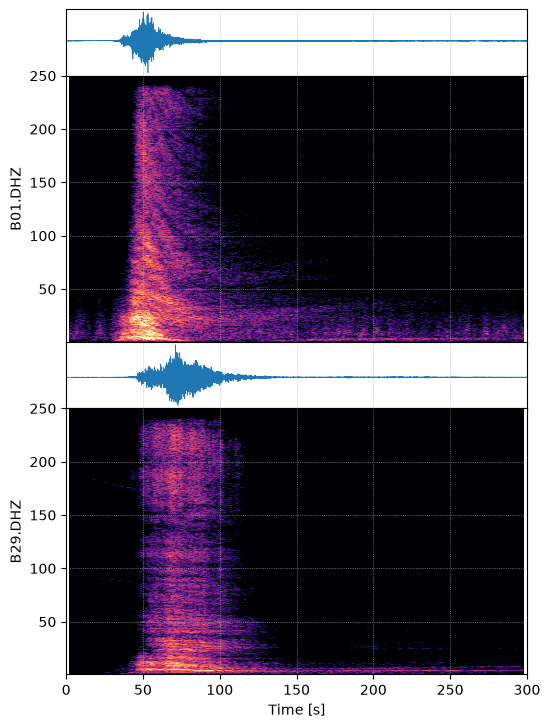

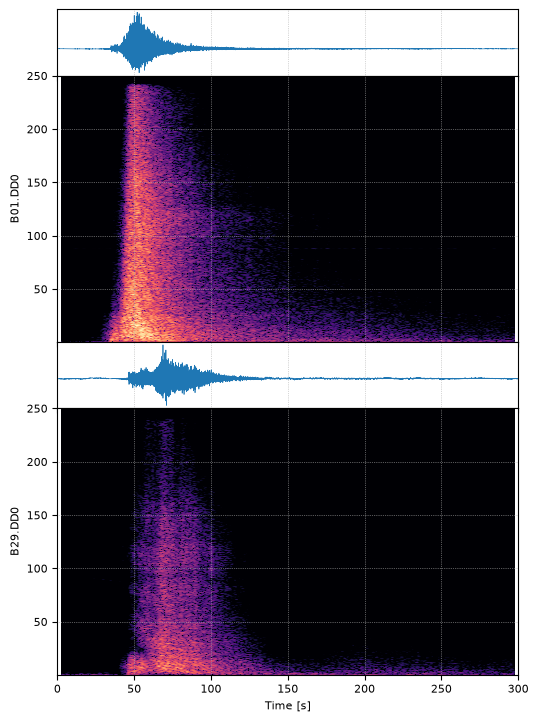

In [27]:

from flovopy.processing.spectrograms import icewebSpectrogram
iwobj = icewebSpectrogram(seismic_subset)
iwobj.precompute()
iwobj.plot(dbscale=True, equal_scale=True, fmax=250.0, clim=[1e-7, 1e-4], cmap='magma', add_colorbar=False, outfile=OUT_DIR / 'near_far_seismic_spectrogram.png');

iwobji = icewebSpectrogram(infrasound_subset)
iwobji.precompute()
iwobji.plot(dbscale=True, equal_scale=True, fmax=250.0, clim=[2e-2, 2e1], cmap='magma', add_colorbar=False, outfile=OUT_DIR / 'near_far_infrasound_spectrogram.png');
